[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/30_QML_Defences_Against_ML_Attacks/HybridQNN_AdversarialDefence_Azimi2026.ipynb)

# Hybrid quantum-classical CNN (QShield) as a defence against adversarial examples: Azimi et al. 2026, step by step

**Paper.** Navid Azimi, Aditya Prakash, Yao Wang, Li Xiong. *QShield: Securing Neural Networks Against Adversarial Attacks using Quantum Circuits.* arXiv:2604.10933 (v2, Aug 2026). DOI [10.48550/arXiv.2604.10933](https://doi.org/10.48550/arxiv.2604.10933). Code released by the authors: <https://github.com/n-azimi/QShield>.

**What this notebook does.** It rebuilds the paper's pipeline on a CPU simulator: a ResNet-18 backbone whose logits are encoded as rotation angles of a 4-qubit noisy circuit (PennyLane, density-matrix simulation), a small MLP that fuses the classical and quantum class probabilities, and an evaluation under FGSM and PGD (plus a black-box Square attack) with the paper's perturbation budgets. A plain DNN and the plain CNN are trained on the same data as baselines. The authors' own quantum layer (`qnn_toolkit.py`, commit pinned below) is imported and reused; only the circuit *execution* is replaced by an exactly equivalent batched simulator (equivalence is asserted in the notebook) because the authors' per-sample PennyLane loop is about 100 times too slow for a classroom CPU run.

**How to run.** Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` (default) is a demo with small subsets and finishes in roughly 10 minutes; `FAST_MODE = False` uses larger subsets and all three datasets (about 1.5 hours on a CPU, see the configuration cell). No account or token is needed: MNIST, CIFAR-10 (Hugging Face mirror `uoft-cs/cifar10`, public) and OrganAMNIST (Zenodo, MedMNIST v2) are public. If you hit Hugging Face rate limits, add your own token as a Colab Secret named `HF_TOKEN`; the notebook reads it from there and nowhere else.

**What you get at the end.** Clean accuracy (the paper's ODR) and attack success rate (ASR) for DNN, CNN and the four entanglement variants, a side-by-side table against the paper's Figures 12, 14, 15 and 16 with a verdict per claim, drawings of the executed quantum circuits, and an extra *adaptive-attack* experiment that tests whether the claimed robustness is real or an artefact of how gradients are (not) propagated through the quantum branch.

## The paper in one page

**Problem.** Image classifiers (here MNIST digits, OrganAMNIST abdominal CT slices, CIFAR-10 photos) are fooled by tiny perturbations (adversarial examples). The paper asks whether bolting a noisy parameterised quantum circuit onto a CNN makes the *attack harder*.

**Method (QShield, called "HQCNN" in the paper and `QNN` in the code).**
1. A CNN backbone (modified ResNet-18) produces class logits `y_c`.
2. A forward hook captures the activations of a chosen layer (Algorithm 1). Those features are standardised per sample, brought to 3n numbers (n = number of qubits), and mapped to rotation angles `pi * tanh(.)` (Algorithm 2).
3. A circuit on n qubits applies, per qubit, `RX, RY, RZ` with those angles, then an entangling CNOT block (none / linear / star / full), then a per-qubit *mixed noise* channel (depolarising 0.4, amplitude damping 0.3, phase damping 0.3 of a base strength) (Eq. 13-25). All 2^n basis-state probabilities are measured, truncated/padded to K classes and normalised (Eq. 26-29).
4. A small MLP `g(f)` (7 -> 128 -> 128 -> 128 -> 1, LeakyReLU, BatchNorm, sigmoid) maps seven statistics of the two probability vectors to a weight `alpha` in [0, 1] (Algorithm 3). The final prediction mixes the *square roots* (amplitudes) of both distributions: `a = alpha*sqrt(p_c) + sqrt(1-alpha^2)*sqrt(p_q)`, squared and renormalised (Algorithm 4).
5. Everything is trained end to end with NLL loss, Adam, batch 128, 10 epochs.

**Attacks and metrics.** FGSM, PGD, APGD, VMI-FGSM, C&W, DeepFool, One-Pixel, Square (torchattacks / ART) with budgets eps = 32/255 (MNIST), 8/255 (OrganAMNIST), 2/255 (CIFAR-10); attacks are run only on test images the model classified correctly. ODR = clean test accuracy, ASR = share of those images that become misclassified, TTC = train + test time.

**Claims we can test here.**
* Clean accuracy of every model (Fig. 12; headline number 79.59 % for the fully entangled hybrid on CIFAR-10).
* Hybrids have a much lower ASR than the CNN under FGSM and PGD (Figs. 14-16), the Square (black-box) attack being almost neutralised (1-3 % on CIFAR-10).
* Adversarial examples are far more expensive to generate against hybrids (Fig. 17-19, App. B).

**What we cannot check.** APGD, VMI-FGSM, C&W, DeepFool and One-Pixel results (not run here), and absolute wall-clock numbers (the paper simulated every circuit with PennyLane on a laptop GPU machine; we use a verified batched simulator on CPU).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Backbone | ResNet-18, ImageNet weights, 1-channel stem initialised by averaging RGB filters | same (`torchvision` ResNet-18, `weights=DEFAULT`) |
| Quantum layer | PennyLane `default.mixed`, 4 qubits implied by Figs. 4-7 | the authors' `qnn_toolkit.py` at the pinned commit: `n_qubits = max(2, ceil(log2 K)) = 4`, `circuit_depth = 1`, `noise_strength = 0.005`, `mixed` noise, `enhanced_angle` encoding. Noise strength and qubit rule are **not stated in the paper**; they are read from the released code |
| Feature layer fed to the circuit | "last feature-producing layer" | in the released code the forward hook lands on the **final `fc` layer** (the 10/11 class logits), see the diagnostic cell |
| Trainable quantum parameters | rotation angles written as variational parameters (Eq. 2) | the circuit has **no trainable parameters**; all 12 angles are data-dependent. The only trainable parts are the CNN and the fusion MLP |
| Gradient flow | not discussed | the released code **detaches** the angles (`.detach().cpu().numpy()`), so no gradient reaches the CNN through the quantum branch; we reproduce this (`differentiable=False`) and additionally test a fully differentiable variant |
| Training data | full training sets, class-balanced, 10 epochs | **small class-balanced subsets** (`N_TRAIN`) and fewer epochs (`EPOCHS`) because of CPU time; `# CHOICE:` in the configuration cell |
| Test data | full test sets | class-balanced test subset (`N_TEST`) |
| Attacks | torchattacks / ART, 8 attacks | FGSM and PGD (budgets from Table A1) re-implemented in a few lines with torchattacks semantics, plus a simplified Square attack (Linf, margin loss, p_init = 0.8); no extra package needed |
| Attacked images | all correctly classified test images | the first `N_ATTACK` correctly classified test images of each model |
| Runs | one run | one training seed (`SEED = 42`); binomial 95 % intervals are shown for ASR |
| Hardware | MX570A GPU laptop, hours per model | CPU only |

## 1. Setup

In [1]:
# Installs are guarded: nothing is reinstalled when the libraries are already importable (e.g. locally).
# Tested versions: pennylane 0.45.1, torch 2.14.1+cpu, torchvision 0.29.1+cpu, numpy 2.5.4, scikit-learn 1.9.1.
import importlib, subprocess, sys
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except Exception:
    IN_COLAB = False
_missing = []
for _mod in ["pennylane", "torch", "torchvision", "pandas", "pyarrow", "huggingface_hub", "sklearn", "requests"]:
    try:
        importlib.import_module(_mod)
    except Exception:
        _missing.append(_mod)
if _missing:
    _pkgs = {"sklearn": "scikit-learn", "pennylane": "pennylane==0.45.1"}
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install"] + [_pkgs.get(m, m) for m in _missing])
    print("Installed:", _missing, "-> if imports fail below, restart the runtime and run again.")
else:
    print("All required libraries already available (IN_COLAB =", IN_COLAB, ")")

All required libraries already available (IN_COLAB = False )


In [2]:
# ---------------------------------------------------------------- configuration (every tunable constant)
SEED = 42
FAST_MODE = False          # True: ~10 min demo on CIFAR-10 only; False: all three datasets, larger subsets (~1.5 h on CPU)
DATA_DIR = "qc100_data"      # downloads and the authors' code are cached here
QSHIELD_COMMIT = "9c4c85b122689edaf42ef1acb8cd398132e4cd69"   # github.com/n-azimi/QShield, HEAD on 2026-05-11
IBM_TOKEN = ""               # not used: the paper simulates the circuits, no hardware is needed

# CHOICE: subset sizes / epochs are not the paper's (full sets, 10 epochs, hours per model) but what a CPU can do.
if FAST_MODE:
    DATASETS = ["CIFAR10"]
    MODELS = ["DNN", "CNN", "HQCNN-None", "HQCNN-Full"]
    N_TRAIN, N_TEST, EPOCHS = 1500, 500, 2
    N_ATTACK = 100                    # correctly classified test images attacked with FGSM / PGD
    SQUARE_QUERIES, N_SQUARE = 60, 40  # simplified Square attack: queries per image, images
else:
    DATASETS = ["CIFAR10", "MNIST", "OrganAMNIST"]
    MODELS = ["DNN", "CNN", "HQCNN-None", "HQCNN-Linear", "HQCNN-Star", "HQCNN-Full"]
    N_TRAIN, N_TEST, EPOCHS = 1500, 1000, 3
    N_ATTACK = 120
    SQUARE_QUERIES, N_SQUARE = 80, 40

BATCH_SIZE, LR, WEIGHT_DECAY = 128, 1e-3, 1e-4          # paper: batch 128, Adam, NLL loss
NOISE_STRENGTH, CIRCUIT_DEPTH = 0.005, 1                  # from the released code (qnn_settings)
EPS = {"MNIST": 32/255, "OrganAMNIST": 8/255, "CIFAR10": 2/255}   # Table A1
PGD_ALPHA, PGD_STEPS = 2/255, 10                          # Table A1
TORCH_THREADS = 4

In [3]:
import os, io, time, math, zipfile, functools, warnings, json
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torch.optim as optim
import torchvision, torchvision.models as tvmodels
import pennylane as qml
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
warnings.filterwarnings("ignore")

os.makedirs(DATA_DIR, exist_ok=True)
os.environ["TORCH_HOME"] = os.path.abspath(os.path.join(DATA_DIR, "torch_home"))   # ImageNet ResNet-18 weights cache
torch.set_num_threads(TORCH_THREADS)
torch.manual_seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
DEVICE = torch.device("cpu")

# Hugging Face token (only used if a download needs it; none of the datasets here is gated)
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| pennylane", qml.__version__,
      "| numpy", np.__version__, "| FAST_MODE =", FAST_MODE)

torch 2.14.1+cpu | torchvision 0.29.1+cpu | pennylane 0.45.1 | numpy 2.5.4 | FAST_MODE = False


### 1.1 The authors' code, pinned to a commit

We download the repository snapshot at the commit named in the configuration cell and import its quantum module `qnn_toolkit.py` (feature hook, angle encoding, entanglement layers, noise channels, dynamic-weighting MLP, and the PennyLane forward pass). Nothing from the repository is modified.

In [4]:
def fetch_qshield(commit=QSHIELD_COMMIT):
    root = os.path.join(DATA_DIR, "repos")
    target = os.path.join(root, f"QShield-{commit}")
    if not os.path.exists(os.path.join(target, "qnn_toolkit.py")):
        os.makedirs(root, exist_ok=True)
        r = requests.get(f"https://codeload.github.com/n-azimi/QShield/zip/{commit}", timeout=120)
        r.raise_for_status()
        with zipfile.ZipFile(io.BytesIO(r.content)) as z:
            z.extractall(root)
        assert os.path.exists(os.path.join(target, "qnn_toolkit.py")), "unexpected archive layout"
    return target

QSHIELD_DIR = fetch_qshield()
import sys
sys.path.insert(0, QSHIELD_DIR)
import qnn_toolkit as qt
print("authors' code:", QSHIELD_DIR)
print("functions reused:", [n for n in ("FeatureExtractor", "DynamicWeightingModule", "angle_encoding_enhanced",
                                         "apply_entanglement_layer", "apply_noise_operations", "QNN") if hasattr(qt, n)])

authors' code: qc100_data\repos\QShield-9c4c85b122689edaf42ef1acb8cd398132e4cd69
functions reused: ['FeatureExtractor', 'DynamicWeightingModule', 'angle_encoding_enhanced', 'apply_entanglement_layer', 'apply_noise_operations', 'QNN']


## 2. Data
CIFAR-10 comes from the public Hugging Face mirror `uoft-cs/cifar10` (the original Toronto server is very slow), MNIST from `torchvision` (fallback: HF `ylecun/mnist`), OrganAMNIST (MedMNIST v2, axial view, 28x28) from Zenodo. Training and test subsets are **class-balanced** (the authors' notebook also balances classes) and drawn with `numpy` seeded by `SEED`. Images are scaled to [0, 1]; no mean/std normalisation, as in the authors' code (`ToTensor` only).

In [5]:
CLASSES = {
    "MNIST": [str(i) for i in range(10)],
    "CIFAR10": ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"],
    "OrganAMNIST": ["bladder", "femur-left", "femur-right", "heart", "kidney-left", "kidney-right",
                    "liver", "lung-left", "lung-right", "pancreas", "spleen"],
}

def _parquet_arrays(path, img_col, lab_col):
    df = pd.read_parquet(path)
    imgs = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df[img_col]])
    return imgs.astype(np.uint8), df[lab_col].to_numpy().astype(np.int64)

def _hf_parquet(repo, fname):
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo, fname, repo_type="dataset", token=HF_TOKEN or None,
                           cache_dir=os.path.join(DATA_DIR, "hf"))

def load_raw(name):
    # returns uint8 arrays: xtr [N,H,W(,C)], ytr, xte, yte  (cached as .npz)
    cache = os.path.join(DATA_DIR, f"{name}.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["xtr"], z["ytr"], z["xte"], z["yte"]
    if name == "CIFAR10":
        a = []
        for sp in ["train", "test"]:
            a += list(_parquet_arrays(_hf_parquet("uoft-cs/cifar10", f"plain_text/{sp}-00000-of-00001.parquet"), "img", "label"))
    elif name == "MNIST":
        try:
            tr = torchvision.datasets.MNIST(os.path.join(DATA_DIR, "mnist_tv"), train=True, download=True)
            te = torchvision.datasets.MNIST(os.path.join(DATA_DIR, "mnist_tv"), train=False, download=True)
            a = [tr.data.numpy(), tr.targets.numpy(), te.data.numpy(), te.targets.numpy()]
        except Exception as e:
            print("torchvision MNIST failed (", repr(e)[:80], ") -> Hugging Face fallback")
            a = []
            for sp in ["train", "test"]:
                a += list(_parquet_arrays(_hf_parquet("ylecun/mnist", f"mnist/{sp}-00000-of-00001.parquet"), "image", "label"))
    elif name == "OrganAMNIST":
        p = os.path.join(DATA_DIR, "organamnist.npz")
        if not os.path.exists(p):
            r = requests.get("https://zenodo.org/records/10519652/files/organamnist.npz?download=1", timeout=300)
            r.raise_for_status(); open(p, "wb").write(r.content)
        z = np.load(p)
        a = [z["train_images"], z["train_labels"].ravel().astype(np.int64), z["test_images"], z["test_labels"].ravel().astype(np.int64)]
    else:
        raise ValueError(name)
    np.savez_compressed(cache, xtr=a[0], ytr=a[1], xte=a[2], yte=a[3])
    return a

def balanced_subset(y, n_total, rng):
    classes = np.unique(y); per = n_total // len(classes)
    idx = np.concatenate([rng.choice(np.where(y == c)[0], size=min(per, int((y == c).sum())), replace=False) for c in classes])
    return rng.permutation(idx)

def to_tensor(x_u8):
    x = torch.from_numpy(x_u8).float() / 255.0
    return x[:, None] if x.ndim == 3 else x.permute(0, 3, 1, 2).contiguous()      # [N, C, H, W]

DATA = {}
for name in DATASETS:
    xtr, ytr, xte, yte = load_raw(name)
    info = dict(name=name, classes=CLASSES[name], K=len(CLASSES[name]), full_train_shape=xtr.shape, full_test_shape=xte.shape,
                full_train_counts=np.bincount(ytr), full_test_counts=np.bincount(yte))
    itr = balanced_subset(ytr, N_TRAIN, rng); ite = balanced_subset(yte, N_TEST, rng)
    info.update(Xtr=to_tensor(xtr[itr]), ytr=torch.from_numpy(ytr[itr]), Xte=to_tensor(xte[ite]), yte=torch.from_numpy(yte[ite]))
    info["C"], info["H"] = info["Xtr"].shape[1], info["Xtr"].shape[2]
    DATA[name] = info
    del xtr, ytr, xte, yte
    print(f"{name}: full train {info['full_train_shape']}, test {info['full_test_shape']} -> subsets train {tuple(info['Xtr'].shape)}, test {tuple(info['Xte'].shape)}")

CIFAR10: full train (50000, 32, 32, 3), test (10000, 32, 32, 3) -> subsets train (1500, 3, 32, 32), test (1000, 3, 32, 32)


  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  0%|          | 32.8k/9.91M [00:00<00:57, 172kB/s]

  1%|          | 98.3k/9.91M [00:00<00:27, 356kB/s]

  2%|▏         | 197k/9.91M [00:00<00:17, 559kB/s] 

...

100%|██████████| 1.65M/1.65M [00:00<00:00, 2.37MB/s]

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 2.26MB/s]

MNIST: full train (60000, 28, 28), test (10000, 28, 28) -> subsets train (1500, 1, 28, 28), test (1000, 1, 28, 28)


OrganAMNIST: full train (34561, 28, 28), test (17778, 28, 28) -> subsets train (1496, 1, 28, 28), test (990, 1, 28, 28)


## Dataset Exploration and Visualisation

For each dataset that is actually used: shape, classes and class counts of the **real** data, a bar chart of the real class distribution, one real example per class (the paper's Figs. 9-11), and a 2-D projection of the real training images coloured by their ground-truth class. The projection is a PCA of the flattened pixels fitted on the training subset only (the model itself does not angle-encode pixels: it encodes the CNN's output layer, whose angles are shown after training in section 6). The second panel scales the same coordinates to [0, pi], as in the reference notebooks.

===== CIFAR10 =====
full train images: (50000, 32, 32, 3) | full test images: (10000, 32, 32, 3) | pixel range [0, 255] -> [0, 1]
feature names: raw pixels ( 3 channel(s) x 32 x 32 = 3072 values per image )
original label values and counts (full training set):
 label      class  train  test  train_subset  test_subset
     0   airplane   5000  1000           150          100
     1 automobile   5000  1000           150          100
     2       bird   5000  1000           150          100
     3        cat   5000  1000           150          100
     4       deer   5000  1000           150          100
     5        dog   5000  1000           150          100
     6       frog   5000  1000           150          100
     7      horse   5000  1000           150          100
     8       ship   5000  1000           150          100
     9      truck   5000  1000           150          100


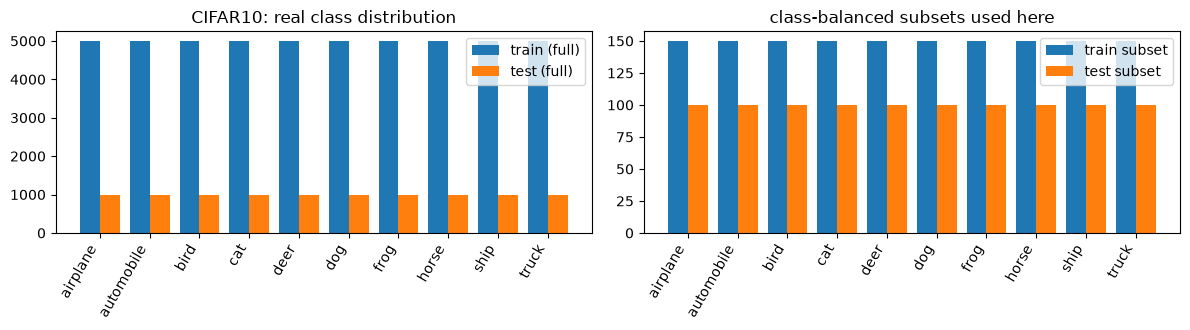

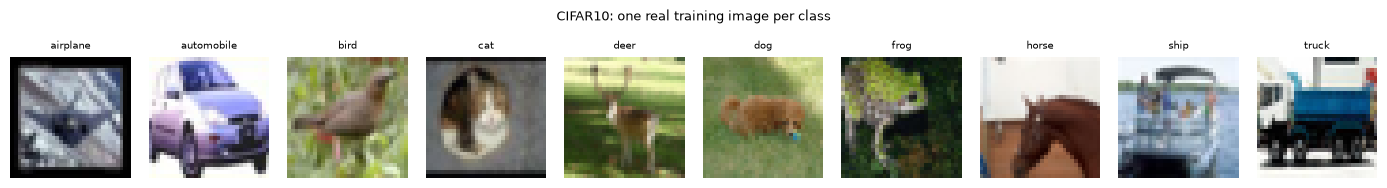

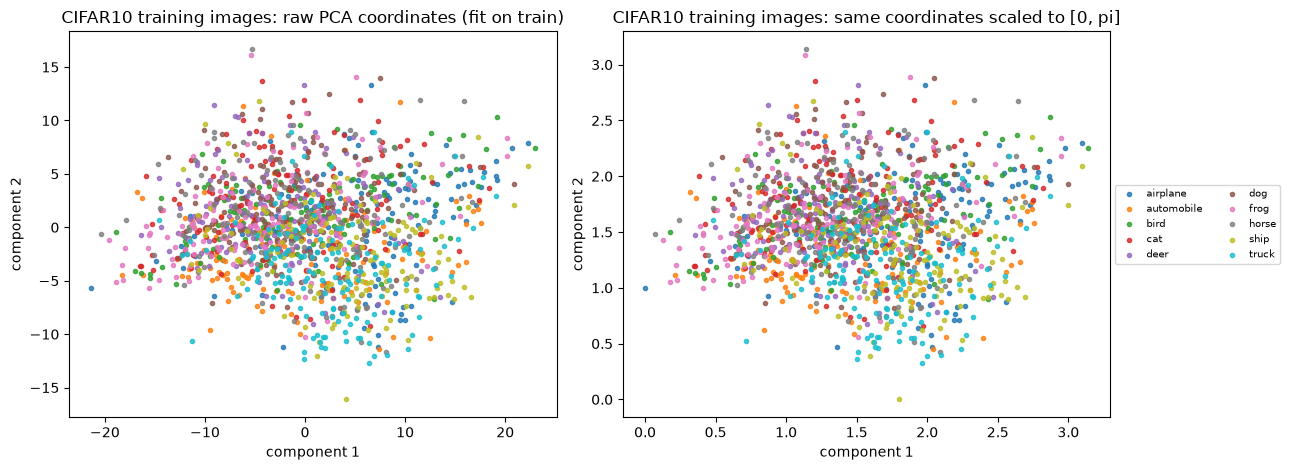

explained variance of the two components: [0.306 0.111] 

===== MNIST =====
full train images: (60000, 28, 28) | full test images: (10000, 28, 28) | pixel range [0, 255] -> [0, 1]
feature names: raw pixels ( 1 channel(s) x 28 x 28 = 784 values per image )
original label values and counts (full training set):
 label class  train  test  train_subset  test_subset
     0     0   5923   980           150          100
     1     1   6742  1135           150          100
     2     2   5958  1032           150          100
     3     3   6131  1010           150          100
     4     4   5842   982           150          100
     5     5   5421   892           150          100
     6     6   5918   958           150          100
     7     7   6265  1028           150          100
     8     8   5851   974           150          100
     9     9   5949  1009           150          100


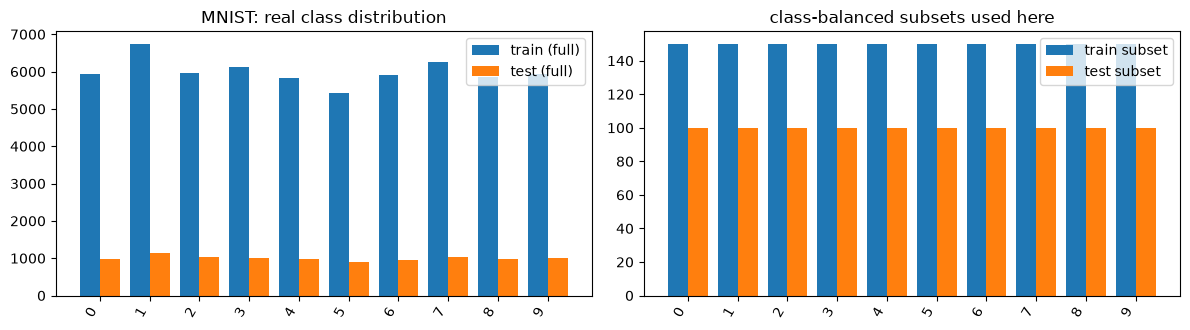

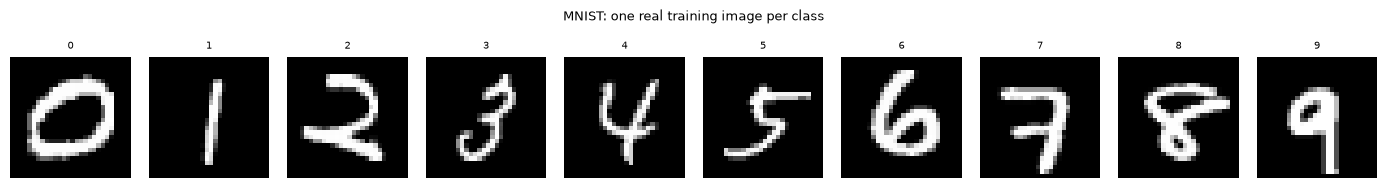

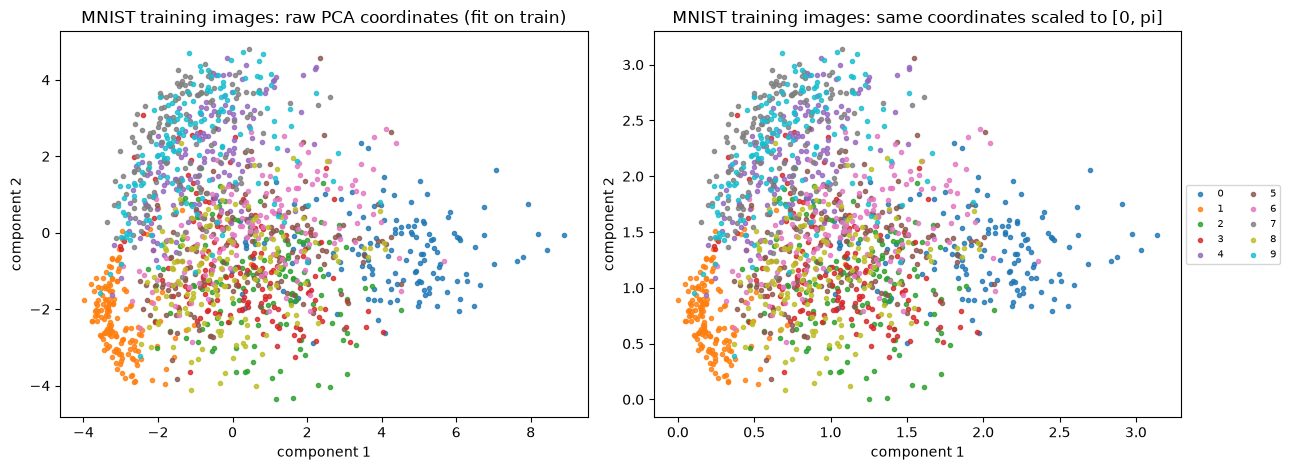

explained variance of the two components: [0.096 0.072] 

===== OrganAMNIST =====
full train images: (34561, 28, 28) | full test images: (17778, 28, 28) | pixel range [0, 255] -> [0, 1]
feature names: raw pixels ( 1 channel(s) x 28 x 28 = 784 values per image )
original label values and counts (full training set):
 label        class  train  test  train_subset  test_subset
     0      bladder   1956  1036           136           90
     1   femur-left   1390   784           136           90
     2  femur-right   1357   793           136           90
     3        heart   1474   785           136           90
     4  kidney-left   3963  2064           136           90
     5 kidney-right   3817  1965           136           90
     6        liver   6164  3285           136           90
     7    lung-left   3919  1747           136           90
     8   lung-right   3929  1813           136           90
     9     pancreas   3031  1622           136           90
    10       spleen   35

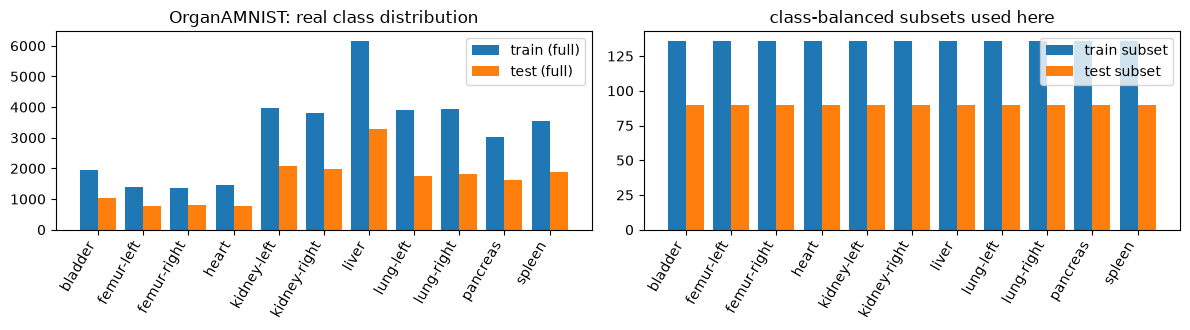

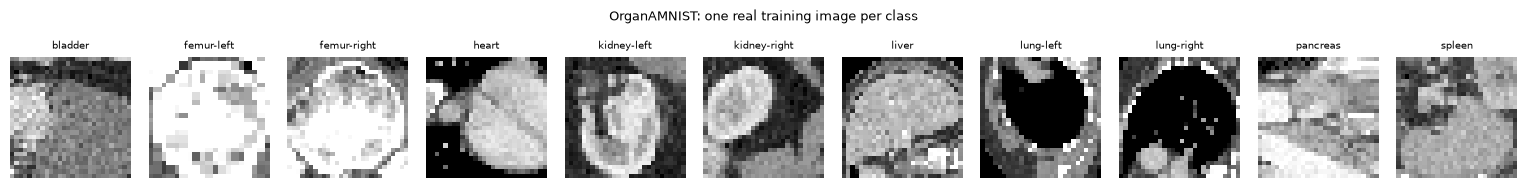

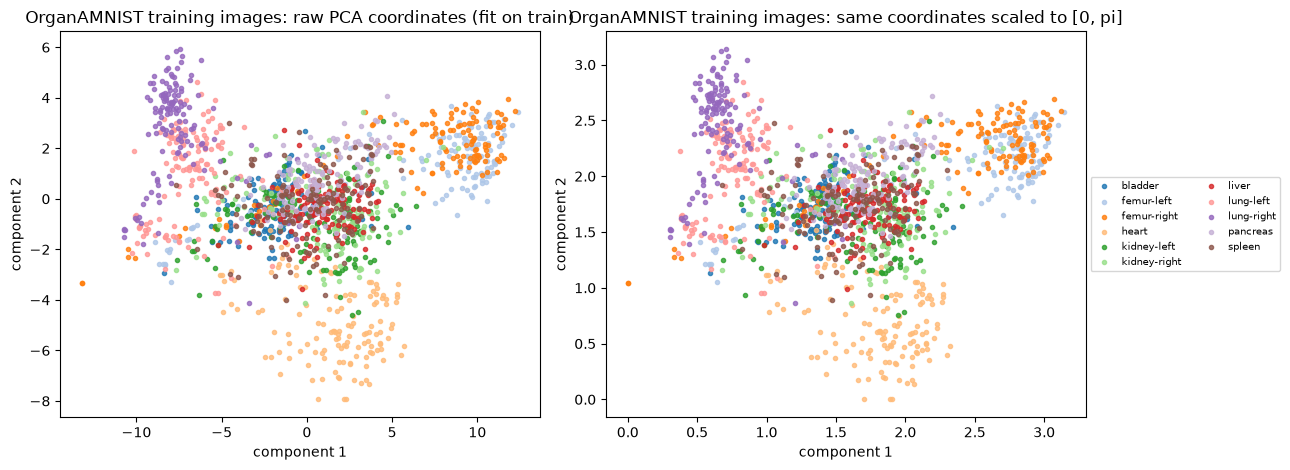

explained variance of the two components: [0.389 0.075] 



In [6]:
palette = lambda k, K=10: plt.get_cmap("tab10" if K <= 10 else "tab20")(k)
for name, d in DATA.items():
    K, cls = d["K"], d["classes"]
    print(f"===== {name} =====")
    print("full train images:", d["full_train_shape"], "| full test images:", d["full_test_shape"], "| pixel range [0, 255] -> [0, 1]")
    print("feature names: raw pixels (", d["C"], "channel(s) x", d["H"], "x", d["H"], "=", d["C"] * d["H"] * d["H"], "values per image )")
    print("original label values and counts (full training set):")
    print(pd.DataFrame({"label": range(K), "class": cls, "train": d["full_train_counts"], "test": d["full_test_counts"],
                        "train_subset": np.bincount(d["ytr"].numpy(), minlength=K), "test_subset": np.bincount(d["yte"].numpy(), minlength=K)}).to_string(index=False))

    fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
    w = 0.4
    ax[0].bar(np.arange(K) - w/2, d["full_train_counts"], w, label="train (full)"); ax[0].bar(np.arange(K) + w/2, d["full_test_counts"], w, label="test (full)")
    ax[0].set_xticks(range(K)); ax[0].set_xticklabels(cls, rotation=60, ha="right"); ax[0].set_title(f"{name}: real class distribution"); ax[0].legend()
    ax[1].bar(np.arange(K) - w/2, np.bincount(d["ytr"].numpy(), minlength=K), w, label="train subset"); ax[1].bar(np.arange(K) + w/2, np.bincount(d["yte"].numpy(), minlength=K), w, label="test subset")
    ax[1].set_xticks(range(K)); ax[1].set_xticklabels(cls, rotation=60, ha="right"); ax[1].set_title("class-balanced subsets used here"); ax[1].legend()
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, K, figsize=(1.4 * K, 1.8))
    for k in range(K):
        i = int((d["ytr"] == k).nonzero()[0, 0]); img = d["Xtr"][i].permute(1, 2, 0).numpy()
        axes[k].imshow(img.squeeze(), cmap="gray" if d["C"] == 1 else None); axes[k].set_title(cls[k], fontsize=7); axes[k].axis("off")
    plt.suptitle(f"{name}: one real training image per class", y=1.02, fontsize=9); plt.tight_layout(); plt.show()

    # PCA of flattened pixels, fitted on the training subset only
    Ftr = d["Xtr"].reshape(len(d["Xtr"]), -1).numpy(); pca = PCA(n_components=2, random_state=SEED).fit(Ftr)
    Ztr = pca.transform(Ftr); Zte = pca.transform(d["Xte"].reshape(len(d["Xte"]), -1).numpy())
    sc = MinMaxScaler((0, np.pi)).fit(Ztr); Atr = sc.transform(Ztr); Ate = np.clip(sc.transform(Zte), 0, np.pi)
    d["pca"] = (pca, sc)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
    for j, (Z, ttl) in enumerate([(Ztr, "raw PCA coordinates (fit on train)"), (Atr, "same coordinates scaled to [0, pi]")]):
        for k in range(K):
            m = (d["ytr"].numpy() == k); ax[j].scatter(Z[m, 0], Z[m, 1], s=9, color=palette(k, K), label=cls[k], alpha=0.8)
        ax[j].set_title(f"{name} training images: {ttl}"); ax[j].set_xlabel("component 1"); ax[j].set_ylabel("component 2")
    ax[1].legend(fontsize=7, ncol=2, loc="center left", bbox_to_anchor=(1.0, 0.5)); plt.tight_layout(); plt.show()
    print("explained variance of the two components:", np.round(pca.explained_variance_ratio_, 3), "\n")

## 3. Models

* **DNN**: 3 (MNIST/OrganAMNIST) or 4 (CIFAR-10) fully connected blocks (FC, BatchNorm, ReLU, Dropout 0.2), log-softmax output (Sect. 4.1).
* **CNN**: ResNet-18 with ImageNet weights, 1-channel stem for the grayscale sets, new `fc` layer, log-softmax (Sect. 4.2). Class `CNNNet` below has the same structure as the authors' notebook class `CNN`.
* **HQCNN-{None, Linear, Star, Full}**: the authors' `qnn_toolkit.QNN` wrapping a fresh CNN. Our wrapper adds two switches: `backend="fast"` runs the exactly equivalent batched simulator defined next, `backend="pennylane"` calls the authors' original per-sample PennyLane loop; `differentiable=True` lets gradients flow into the quantum branch (the authors' code does not).

### 3.1 Batched exact simulator of the authors' circuit
The authors' circuit is, per sample: `RX, RY, RZ` on each of the 4 qubits (angles from the CNN features), a CNOT network, then per qubit depolarising(0.4 p), amplitude damping(0.3 p) and phase damping(0.3 p) with p = 0.005, and `probs` of all 16 basis states. Because the encoded state is a product state and all gates are Clifford permutations or single-qubit channels, an exact density-matrix simulation for a whole batch is a handful of 16x16 matrix products in PyTorch. Section 4 asserts that its output equals the authors' PennyLane circuit.

In [7]:
# Batched exact density-matrix simulator of the QShield circuit (verified against the authors' PennyLane circuit in section 4)
import torch, math, numpy as np
CDT = torch.complex64
def _bit(i, q, n): return (i >> (n-1-q)) & 1
def cnot_perm(n, ent):
    """Basis permutation f: index i -> index after the CNOT network (wire 0 = most significant bit, as in PennyLane)."""
    pairs=[]
    if ent=="linear_entanglement_ansatz": pairs=[(i,i+1) for i in range(n-1)]
    elif ent=="full_entanglement_ansatz": pairs=[(i,j) for i in range(n) for j in range(i+1,n)]
    elif ent=="star_entanglement_ansatz": pairs=[(0,i) for i in range(1,n)]
    f=[]
    for i in range(2**n):
        bits=[_bit(i,q,n) for q in range(n)]
        for c,t in pairs: bits[t]^=bits[c]
        f.append(sum(b<<(n-1-q) for q,b in enumerate(bits)))
    return torch.tensor(f)
def _embed(K, q, n):
    mats=[torch.eye(2,dtype=CDT)]*n; mats=list(mats); mats[q]=K.to(CDT)
    out=mats[0]
    for m in mats[1:]: out=torch.kron(out,m)
    return out
def kraus_ops(p, n, wD=0.4, wA=0.3, wP=0.3):
    I=torch.eye(2,dtype=CDT); X=torch.tensor([[0,1],[1,0]],dtype=CDT); Y=torch.tensor([[0,-1j],[1j,0]],dtype=CDT); Z=torch.tensor([[1,0],[0,-1]],dtype=CDT)
    pd,ga,gp=wD*p,wA*p,wP*p
    D=[math.sqrt(1-pd)*I]+[math.sqrt(pd/3)*P for P in (X,Y,Z)]
    A=[torch.tensor([[1,0],[0,math.sqrt(1-ga)]],dtype=CDT), torch.tensor([[0,math.sqrt(ga)],[0,0]],dtype=CDT)]
    P_=[torch.tensor([[1,0],[0,math.sqrt(1-gp)]],dtype=CDT), torch.tensor([[0,0],[0,math.sqrt(gp)]],dtype=CDT)]
    seq=[]
    for q in range(n):                     # same order as the repo: per wire D, then A, then P
        for chan in (D,A,P_): seq.append([_embed(K,q,n) for K in chan])
    return seq
def simulate_probs(rx, ry, rz, perm, kraus_seq):
    """Exact density-matrix simulation, batched. rx,ry,rz: [B,n] angles -> probabilities [B,2^n]. Differentiable."""
    B,n=rx.shape
    c1,s1=torch.cos(rx/2),torch.sin(rx/2); c2,s2=torch.cos(ry/2),torch.sin(ry/2)
    a0=torch.complex(c1,torch.zeros_like(c1)); a1=torch.complex(torch.zeros_like(s1),-s1)      # RX|0>
    b0=c2*a0-s2*a1; b1=s2*a0+c2*a1                                                              # RY
    e=torch.exp(torch.complex(torch.zeros_like(rz),-rz/2)); psi0=b0*e; psi1=b1*torch.conj(e)    # RZ
    psi=torch.stack([psi0,psi1],-1).to(CDT)                                                     # [B,n,2]
    st=psi[:,0]
    for q in range(1,n): st=(st[:,:,None]*psi[:,q][:,None,:]).reshape(B,-1)
    rho=st[:,:,None]*torch.conj(st)[:,None,:]
    inv=torch.argsort(perm); rho=rho[:,inv][:,:,inv]
    for chan in kraus_seq:
        rho=sum(K@rho@K.conj().T for K in chan)
    return torch.real(torch.diagonal(rho,dim1=1,dim2=2))

In [8]:
class DNNNet(nn.Module):
    def __init__(self, in_dim, K, hidden):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(0.2)]; d = h
        self.body, self.out = nn.Sequential(*layers), nn.Linear(d, K)
    def forward(self, x):
        return F.log_softmax(self.out(self.body(x.reshape(x.size(0), -1))), dim=1)

class CNNNet(nn.Module):                       # same structure as `CNN` in the authors' notebook
    def __init__(self, K, in_channels):
        super().__init__()
        self.resnet18 = tvmodels.resnet18(weights=tvmodels.ResNet18_Weights.DEFAULT)
        if in_channels == 1:
            old = self.resnet18.conv1
            self.resnet18.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
            with torch.no_grad():
                self.resnet18.conv1.weight[:] = old.weight.mean(dim=1, keepdim=True)
        self.resnet18.fc = nn.Linear(self.resnet18.fc.in_features, K)
        self.logsoftmax = nn.LogSoftmax(dim=1)
    def forward(self, x):
        return self.logsoftmax(self.resnet18(x))

ENT = {"None": "no_entanglement_ansatz", "Linear": "linear_entanglement_ansatz",
       "Star": "star_entanglement_ansatz", "Full": "full_entanglement_ansatz"}

def fast_forward(q, x, differentiable=False, parts=False):
    # Line-by-line port of qt.hybrid_forward(); only the circuit call is replaced by simulate_probs().
    out = q.cnn_model(x); feats = q.cnn_model.get_features()                         # classical logits + hooked features
    rx, ry, rz = qt.angle_encoding_enhanced(feats, q.num_qubits)                    # Algorithm 2 (authors' function)
    if not differentiable:                                                          # the authors' code detaches the angles
        rx, ry, rz = rx.detach(), ry.detach(), rz.detach()
    probs = simulate_probs(rx, ry, rz, q._perm, q._kraus)
    K = q.output_dim
    qp = probs[:, :K] if probs.shape[1] >= K else F.pad(probs, (0, K - probs.shape[1]))
    eps = 1e-8
    alpha = torch.clamp(q.dynamic_weight_module(out, torch.log(qp)), 0.0, 1.0)      # Algorithm 3
    cp = torch.clamp(F.softmax(out, dim=1), min=eps)
    qpn = torch.clamp(qp / (qp.sum(dim=1, keepdim=True) + eps), min=eps)
    beta = torch.sqrt(torch.clamp(1 - alpha ** 2, min=eps, max=1.0))
    amp = alpha * torch.sqrt(cp) + beta * torch.sqrt(qpn)                           # Algorithm 4
    hp = amp ** 2; hp = hp / (hp.sum(dim=1, keepdim=True) + eps); hp = torch.clamp(hp, min=eps)
    if parts:
        return torch.log(hp), dict(alpha=alpha.squeeze(1), pq=qpn, pc=cp, angles=torch.stack([rx, ry, rz], -1), feats=feats)
    return torch.log(hp)

class HQCNN(nn.Module):
    def __init__(self, K, in_channels, ent_key):
        super().__init__()
        self.ent_key, self.backend, self.differentiable = ent_key, "fast", False
        self.qnn = qt.QNN(cnn_model=CNNNet(K, in_channels), device=DEVICE, output_dim=K, circuit_depth=CIRCUIT_DEPTH,
                          noise_strength=NOISE_STRENGTH, input_noise_injection=False, entanglement_type=ENT[ent_key],
                          use_dynamic_weights=True, encoding_method="enhanced_angle", noise_model="mixed")
        self.qnn._perm = cnot_perm(self.qnn.num_qubits, ENT[ent_key])
        self.qnn._kraus = kraus_ops(NOISE_STRENGTH, self.qnn.num_qubits)
    def forward(self, x):
        if self.backend == "pennylane":
            return self.qnn(x)                                   # the authors' original forward pass
        return fast_forward(self.qnn, x, self.differentiable)

def build_model(kind, d):
    torch.manual_seed(SEED)
    if kind == "DNN":
        hidden = [1024, 512, 256, 128] if d["name"] == "CIFAR10" else [512, 256, 128]
        return DNNNet(d["C"] * d["H"] * d["H"], d["K"], hidden)
    if kind == "CNN":
        return CNNNet(d["K"], d["C"])
    return HQCNN(d["K"], d["C"], kind.split("-")[1])

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
d0 = DATA[DATASETS[0]]
for kind in MODELS:
    print(f"{kind:13s} trainable parameters on {d0['name']}: {n_params(build_model(kind, d0)):,}")

DNN           trainable parameters on CIFAR10: 3,840,906

CNN           trainable parameters on CIFAR10: 11,181,642


HQCNN-None    trainable parameters on CIFAR10: 11,216,331


HQCNN-Linear  trainable parameters on CIFAR10: 11,216,331


HQCNN-Star    trainable parameters on CIFAR10: 11,216,331


HQCNN-Full    trainable parameters on CIFAR10: 11,216,331


## 4. Does the fast simulator equal the authors' PennyLane circuit?

For each entanglement pattern we run the authors' original `QNN.forward` (per-sample `default.mixed` qnode) and our `fast_forward` on the same images with the same random seed (Algorithm 2's orthogonal expansion draws a fresh random matrix at every call, so the seed must match) and require the outputs to agree to float32 precision. We also record the speed of both paths and which layer the hook captured.

In [9]:
x_chk = DATA[DATASETS[0]]["Xte"][:8]
rows = []
for key in ["None", "Linear", "Star", "Full"]:
    m = build_model(f"HQCNN-{key}", DATA[DATASETS[0]]).eval()
    with torch.no_grad():
        m.backend = "pennylane"; torch.manual_seed(1); t = time.time(); a = m(x_chk); t_pl = time.time() - t
        m.backend = "fast";      torch.manual_seed(1); t = time.time(); b = m(x_chk); t_fast = time.time() - t
    diff = (a - b).abs().max().item()
    assert diff < 1e-4, f"fast simulator differs from the authors' PennyLane circuit ({key}): {diff}"
    rows.append(dict(entanglement=key, max_abs_diff_log_probs=diff, seconds_pennylane_8_images=round(t_pl, 2), seconds_fast_8_images=round(t_fast, 3)))
print(pd.DataFrame(rows).to_string(index=False))
f = m.qnn.cnn_model.features
print("\nfeatures captured by the forward hook:", tuple(f.shape), "-> this is the final fc layer (class logits), n_qubits =", m.qnn.num_qubits,
      "(", 3 * m.qnn.num_qubits, "angles needed )")
print("EQUIVALENCE ASSERTED: fast batched simulator == authors' PennyLane default.mixed circuit")

entanglement  max_abs_diff_log_probs  seconds_pennylane_8_images  seconds_fast_8_images
        None            4.768372e-07                        1.16                  0.880
      Linear            4.768372e-07                        0.84                  0.109
        Star            4.768372e-07                        0.63                  0.216
        Full            4.768372e-07                        0.87                  0.329

features captured by the forward hook: (8, 10) -> this is the final fc layer (class logits), n_qubits = 4 ( 12 angles needed )
EQUIVALENCE ASSERTED: fast batched simulator == authors' PennyLane default.mixed circuit


## Quantum Circuit Architecture

The drawings below are produced by `qml.draw_mpl` on the **qnode object the authors' code actually builds and executes** (we capture it while `QNN.forward` runs, together with the arguments of one real call; the angles are those of a real test image). One drawing per entanglement pattern. The qubit count is `max(2, ceil(log2 K))`, which gives 4 qubits for the 10-class and 11-class datasets.

**Assumptions where the paper omits details (all read from the released code).** 4 qubits; one layer (`circuit_depth = 1`); base noise strength 0.005 split 0.4 / 0.3 / 0.3 over depolarising / amplitude damping / phase damping; gate order `RX, RY, RZ`; measurement of all four qubits in the computational basis (16 probabilities, the first K are kept). The paper writes the rotations as variational parameters `theta`; in the code they are **the encoded data**, so the circuit has no trainable parameters.

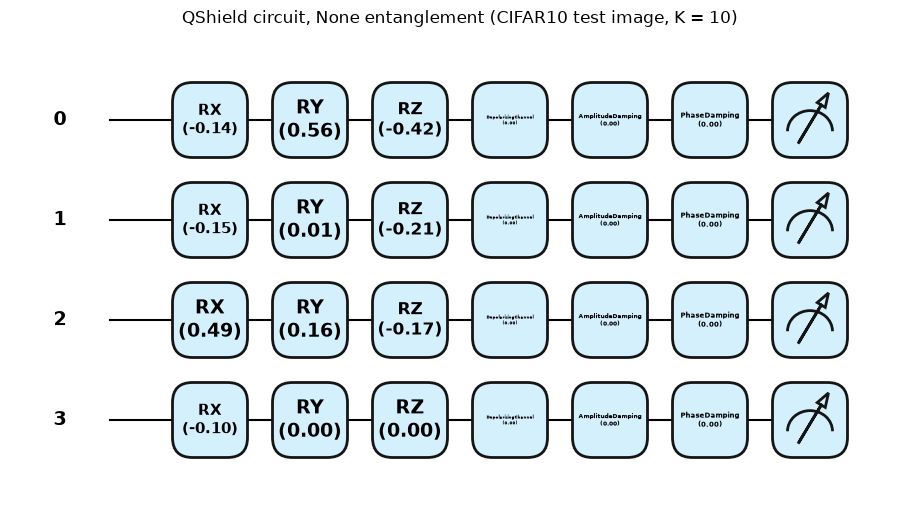

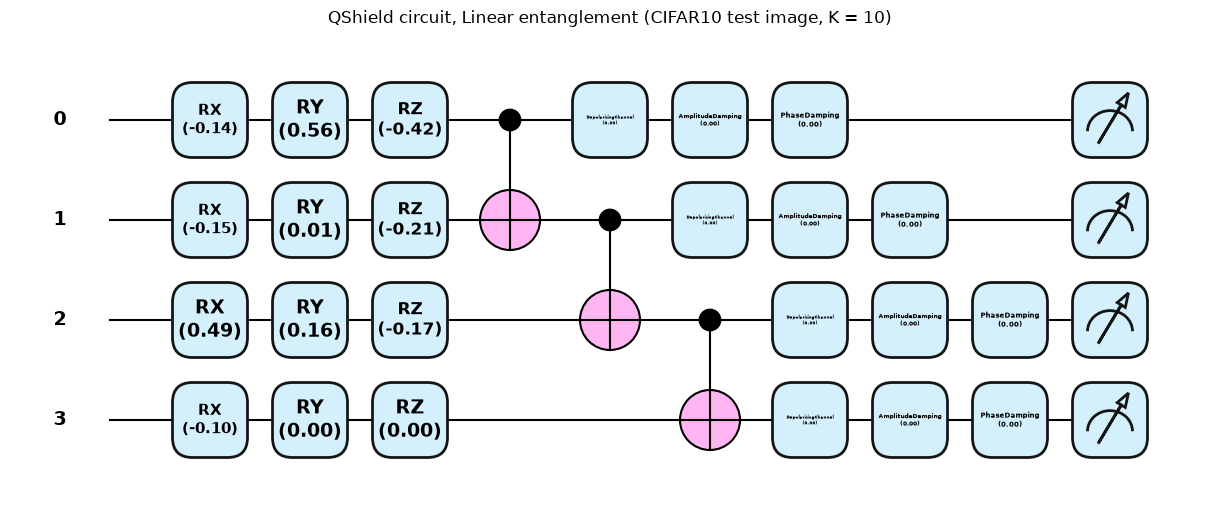

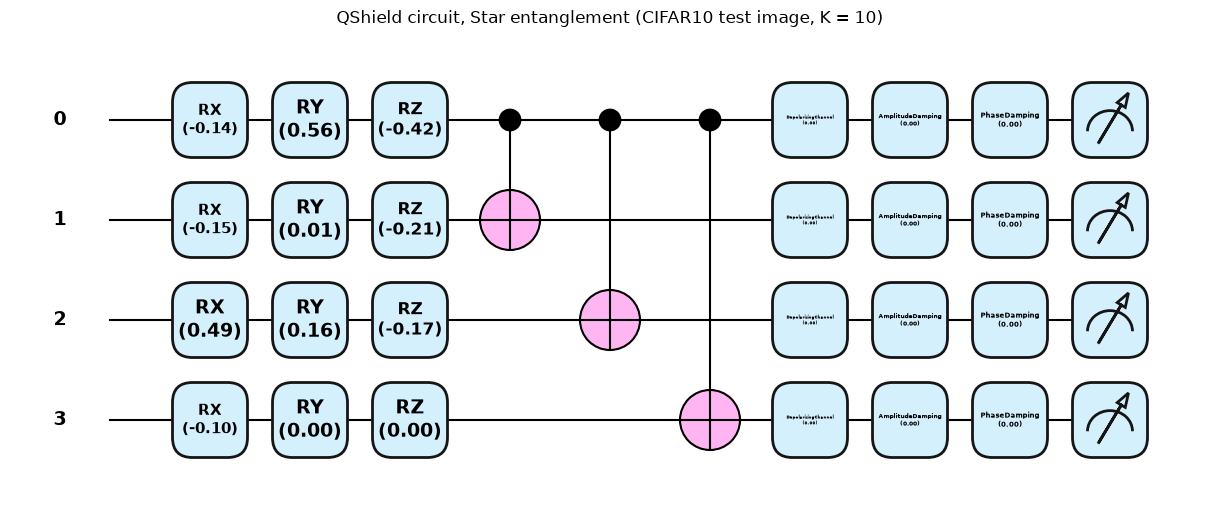

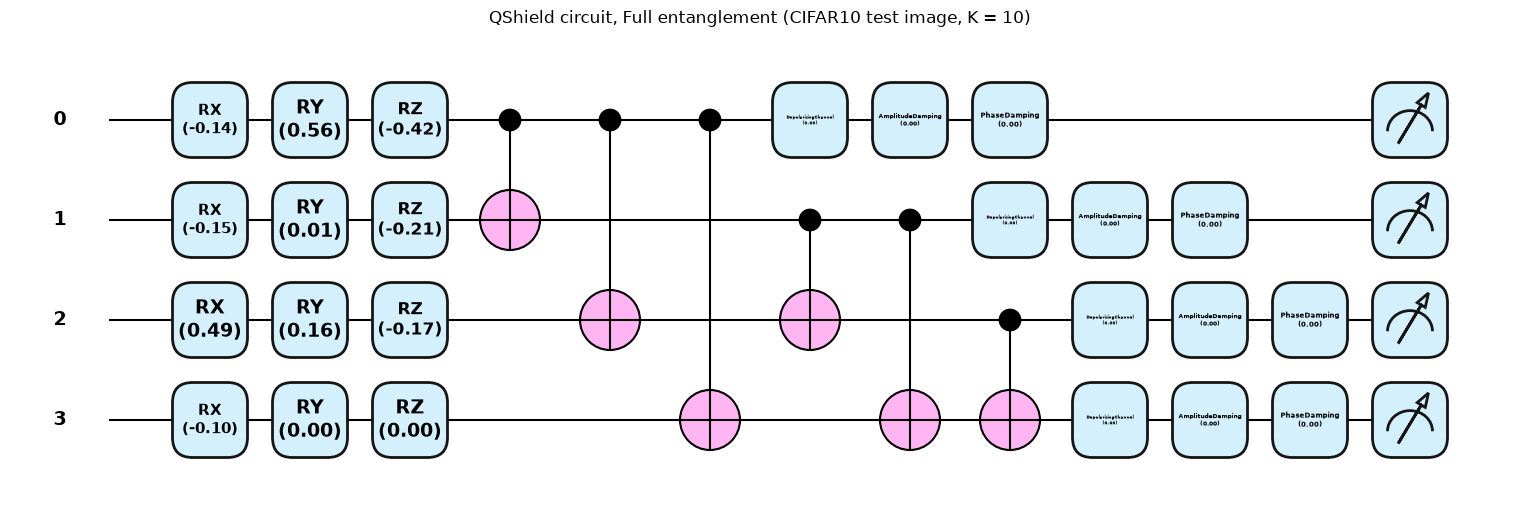

entanglement  qubits  depth  gates  data_encoded_angles  trainable_quantum_params                                                                                                gate_counts
        None       4      6     24                   12                         0            {'RX': 4, 'RY': 4, 'RZ': 4, 'DepolarizingChannel': 4, 'AmplitudeDamping': 4, 'PhaseDamping': 4}
      Linear       4      9     27                   12                         0 {'RX': 4, 'RY': 4, 'RZ': 4, 'CNOT': 3, 'DepolarizingChannel': 4, 'AmplitudeDamping': 4, 'PhaseDamping': 4}
        Star       4      9     27                   12                         0 {'RX': 4, 'RY': 4, 'RZ': 4, 'CNOT': 3, 'DepolarizingChannel': 4, 'AmplitudeDamping': 4, 'PhaseDamping': 4}
        Full       4     11     30                   12                         0 {'RX': 4, 'RY': 4, 'RZ': 4, 'CNOT': 6, 'DepolarizingChannel': 4, 'AmplitudeDamping': 4, 'PhaseDamping': 4}



Trainable parameters of the whole hybrid (CNN + fusion MLP): 11,216,331 | of the fusion MLP: 34,689 | of the quantum circuit: 0
Equivalence asserted: drawn qnode probabilities == fast simulator probabilities (atol 1e-5)


In [10]:
import contextlib
@contextlib.contextmanager
def capture_qnodes():
    calls, nodes = [], []
    orig = qml.qnode
    def spy(*a, **k):
        dec = orig(*a, **k)
        def wrap(fn):
            @functools.wraps(fn)
            def rec(*args, **kw):
                calls.append(args); return fn(*args, **kw)
            node = dec(rec); nodes.append(node); return node
        return wrap
    qml.qnode = spy
    try:
        yield nodes, calls
    finally:
        qml.qnode = orig

dd = DATA[DATASETS[0]]
circuit_rows = []
for key in ["None", "Linear", "Star", "Full"]:
    m = build_model(f"HQCNN-{key}", dd).eval()
    m.backend = "pennylane"
    with capture_qnodes() as (nodes, calls), torch.no_grad():
        torch.manual_seed(1); m(dd["Xte"][:1])
    node, args = nodes[-1], calls[-1]
    fig, ax = qml.draw_mpl(node, decimals=2, style="pennylane")(*args)
    fig.suptitle(f"QShield circuit, {key} entanglement ({dd['name']} test image, K = {dd['K']})", y=1.02); plt.show()
    res = qml.specs(node)(*args)["resources"]
    # equivalence: the captured circuit == the batched simulator, for these very angles
    p_pl = np.asarray(node(*args));
    a_ = [torch.tensor(np.asarray(v), dtype=torch.float32)[None] for v in args[:3]]
    p_fast = simulate_probs(*a_, m.qnn._perm, m.qnn._kraus)[0].numpy()
    assert np.allclose(p_pl, p_fast, atol=1e-5), "drawn circuit and simulator disagree"
    circuit_rows.append(dict(entanglement=key, qubits=res.num_allocs, depth=res.depth, gates=res.num_gates,
                             data_encoded_angles=int(sum(np.size(a) for a in args[:3])), trainable_quantum_params=0,
                             gate_counts=dict(res.gate_types)))
print(pd.DataFrame(circuit_rows).to_string(index=False))
print("\nTrainable parameters of the whole hybrid (CNN + fusion MLP):", f"{n_params(build_model('HQCNN-Full', dd)):,}",
      "| of the fusion MLP:", f"{n_params(build_model('HQCNN-Full', dd).qnn.dynamic_weight_module):,}", "| of the quantum circuit: 0")
print("Equivalence asserted: drawn qnode probabilities == fast simulator probabilities (atol 1e-5)")

## 5. Training (Sect. 6.4)
Adam (lr 1e-3, weight decay 1e-4), NLL loss on the (hybrid) log-probabilities, batch 128, `EPOCHS` epochs on the class-balanced training subset. Wall-clock training plus test time is the paper's TTC (here with the fast simulator, so absolute values are not comparable with the paper's PennyLane timings).

In [11]:
@torch.no_grad()
def predict(model, X, bs=250):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(model(X[i:i + bs]))
    return torch.cat(out)

def train(model, d, epochs=EPOCHS):
    torch.manual_seed(SEED)
    opt = optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY); lossf = nn.NLLLoss()
    X, Y = d["Xtr"], d["ytr"]; hist = []; t0 = time.time()
    g = torch.Generator().manual_seed(SEED)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(X), generator=g); tl = tc = 0
        for i in range(0, len(X), BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            if len(idx) < 2: continue
            opt.zero_grad(); out = model(X[idx]); loss = lossf(out, Y[idx]); loss.backward(); opt.step()
            tl += loss.item() * len(idx); tc += (out.argmax(1) == Y[idx]).sum().item()
        hist.append(dict(epoch=ep + 1, loss=tl / len(X), train_acc=tc / len(X)))
    return pd.DataFrame(hist), time.time() - t0

RES = {}       # RES[dataset][model] = dict(model, train_hist, t_train, ...)
for name in DATASETS:
    d = DATA[name]; RES[name] = {}
    for kind in MODELS:
        model = build_model(kind, d)
        hist, t_train = train(model, d)
        t0 = time.time(); torch.manual_seed(SEED); logp = predict(model, d["Xte"]); t_test = time.time() - t0
        acc = (logp.argmax(1) == d["yte"]).float().mean().item()
        RES[name][kind] = dict(model=model, hist=hist, t_train=t_train, t_test=t_test, odr=acc)
        print(f"[{name}] {kind:13s} train acc {hist.train_acc.iloc[-1]:.3f} | test acc (ODR) {acc:.4f} | TTC {t_train + t_test:7.1f} s")

[CIFAR10] DNN           train acc 0.388 | test acc (ODR) 0.3580 | TTC     8.8 s


[CIFAR10] CNN           train acc 0.826 | test acc (ODR) 0.5340 | TTC   243.0 s


[CIFAR10] HQCNN-None    train acc 0.605 | test acc (ODR) 0.4510 | TTC   240.5 s


[CIFAR10] HQCNN-Linear  train acc 0.393 | test acc (ODR) 0.2340 | TTC   198.9 s


[CIFAR10] HQCNN-Star    train acc 0.603 | test acc (ODR) 0.4930 | TTC   203.3 s


...

[OrganAMNIST] CNN           train acc 0.941 | test acc (ODR) 0.5434 | TTC   145.4 s


[OrganAMNIST] HQCNN-None    train acc 0.838 | test acc (ODR) 0.5131 | TTC   253.9 s


[OrganAMNIST] HQCNN-Linear  train acc 0.852 | test acc (ODR) 0.4333 | TTC   291.9 s


[OrganAMNIST] HQCNN-Star    train acc 0.840 | test acc (ODR) 0.2283 | TTC   205.4 s


[OrganAMNIST] HQCNN-Full    train acc 0.870 | test acc (ODR) 0.1848 | TTC   180.8 s


### 5.1 Clean accuracy (ODR) and training curves

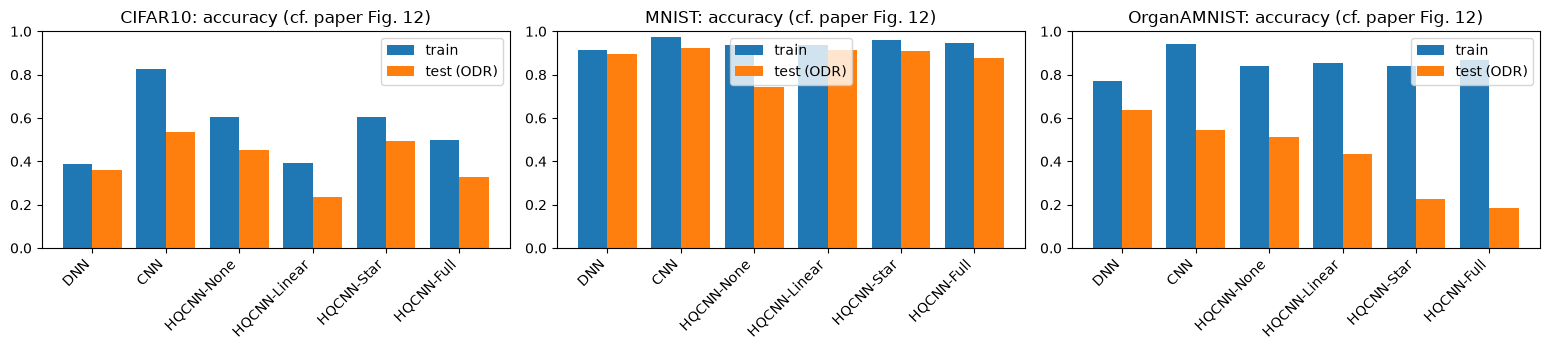

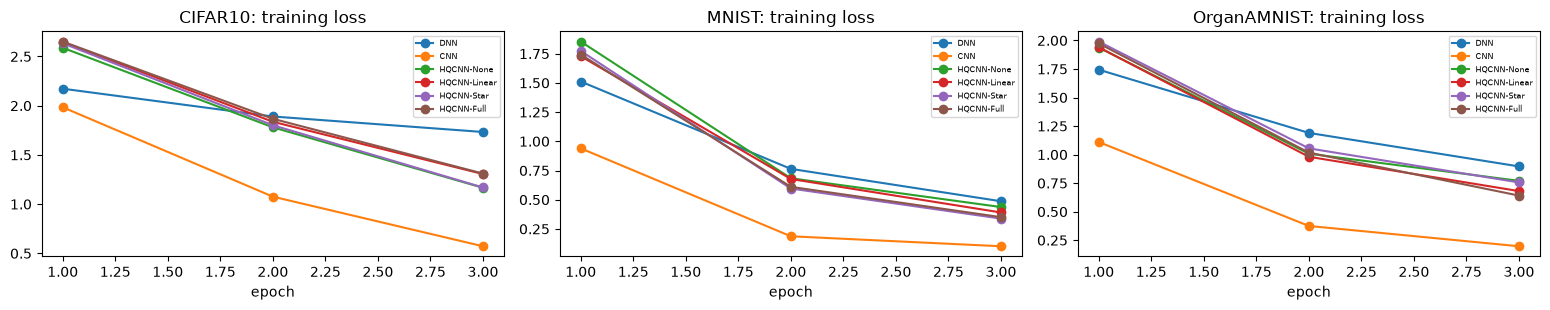

In [12]:
fig, ax = plt.subplots(1, len(DATASETS), figsize=(5.2 * len(DATASETS), 3.6), squeeze=False)
for j, name in enumerate(DATASETS):
    tr = [RES[name][k]["hist"].train_acc.iloc[-1] for k in MODELS]; te = [RES[name][k]["odr"] for k in MODELS]
    xx = np.arange(len(MODELS)); ax[0, j].bar(xx - 0.2, tr, 0.4, label="train"); ax[0, j].bar(xx + 0.2, te, 0.4, label="test (ODR)")
    ax[0, j].set_xticks(xx); ax[0, j].set_xticklabels(MODELS, rotation=45, ha="right"); ax[0, j].set_ylim(0, 1); ax[0, j].set_title(f"{name}: accuracy (cf. paper Fig. 12)"); ax[0, j].legend()
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, len(DATASETS), figsize=(5.2 * len(DATASETS), 3.2), squeeze=False)
for j, name in enumerate(DATASETS):
    for k in MODELS: ax[0, j].plot(RES[name][k]["hist"].epoch, RES[name][k]["hist"].loss, marker="o", label=k)
    ax[0, j].set_title(f"{name}: training loss"); ax[0, j].set_xlabel("epoch"); ax[0, j].legend(fontsize=6)
plt.tight_layout(); plt.show()

## 6. How the hybrid actually behaves (diagnostics)
Before attacking anything we look at what the quantum branch does, because the robustness story depends on it: (i) how large is the fusion weight `alpha`, (ii) how accurate is the quantum branch alone, (iii) how deterministic is the model (Algorithm 2 draws a new random matrix at every forward pass), (iv) the encoded angles of real test images coloured by their true class.

In [13]:
diag = []
for name in DATASETS:
    d = DATA[name]
    for kind in [k for k in MODELS if k.startswith("HQ")]:
        m = RES[name][kind]["model"].eval()
        with torch.no_grad():
            torch.manual_seed(SEED); lp1, p1 = fast_forward(m.qnn, d["Xte"], parts=True)
            torch.manual_seed(SEED + 1); lp2, _ = fast_forward(m.qnn, d["Xte"], parts=True)
        y = d["yte"]
        diag.append(dict(dataset=name, model=kind, mean_alpha=p1["alpha"].mean().item(),
                         classical_branch_acc=(p1["pc"].argmax(1) == y).float().mean().item(),
                         quantum_branch_only_acc=(p1["pq"].argmax(1) == y).float().mean().item(),
                         hybrid_acc=(lp1.argmax(1) == y).float().mean().item(),
                         prediction_agreement_two_passes=(lp1.argmax(1) == lp2.argmax(1)).float().mean().item(),
                         mean_abs_angle_rad=p1["angles"].abs().mean().item(),
                         quantum_prob_std_across_images=p1["pq"].std(dim=0).mean().item(),
                         quantum_prob_max_class_share=torch.bincount(p1["pq"].argmax(1), minlength=d["K"]).max().item() / len(y)))
DIAG = pd.DataFrame(diag); print(DIAG.round(4).to_string(index=False))

    dataset        model  mean_alpha  classical_branch_acc  quantum_branch_only_acc  hybrid_acc  prediction_agreement_two_passes  mean_abs_angle_rad  quantum_prob_std_across_images  quantum_prob_max_class_share
    CIFAR10   HQCNN-None      0.6131                0.4780                   0.1000      0.4520                           0.9500              0.1971                          0.0153                           1.0
    CIFAR10 HQCNN-Linear      0.5533                0.4810                   0.1000      0.2080                           0.8650              0.1966                          0.0127                           1.0
    CIFAR10   HQCNN-Star      0.6775                0.5250                   0.1000      0.4880                           0.9210              0.1941                          0.0138                           1.0
    CIFAR10   HQCNN-Full      0.5696                0.4830                   0.1000      0.3280                           0.8730              0.1953        

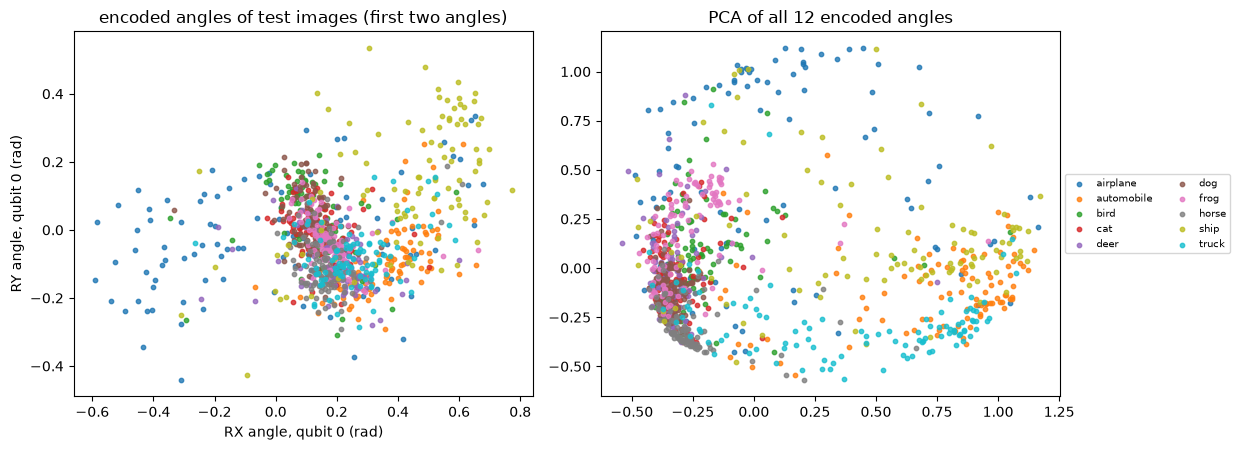

angles lie in (-pi, pi); because the features entering Algorithm 2 are only 10 class logits per image,
the 12 angles are a (random, per-call) linear re-mixing of those logits scaled by 0.1 and squashed by tanh.


In [14]:
# Encoded quantum angles of real test images, coloured by ground-truth class (HQCNN-Full of the first dataset)
name = DATASETS[0]; d = DATA[name]; m = RES[name][[k for k in MODELS if k.startswith("HQ")][-1]]["model"].eval()
with torch.no_grad():
    torch.manual_seed(SEED); _, pr = fast_forward(m.qnn, d["Xte"], parts=True)
ang = pr["angles"].numpy()                      # [N, 4 qubits, 3 rotations]
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6))
for k in range(d["K"]):
    mk = (d["yte"].numpy() == k)
    ax[0].scatter(ang[mk, 0, 0], ang[mk, 0, 1], s=10, color=palette(k, d["K"]), label=d["classes"][k], alpha=0.8)
ax[0].set_xlabel("RX angle, qubit 0 (rad)"); ax[0].set_ylabel("RY angle, qubit 0 (rad)"); ax[0].set_title("encoded angles of test images (first two angles)")
Z = PCA(n_components=2, random_state=SEED).fit_transform(ang.reshape(len(ang), -1))
for k in range(d["K"]):
    mk = (d["yte"].numpy() == k); ax[1].scatter(Z[mk, 0], Z[mk, 1], s=10, color=palette(k, d["K"]), label=d["classes"][k], alpha=0.8)
ax[1].set_title("PCA of all 12 encoded angles"); ax[1].legend(fontsize=7, ncol=2, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout(); plt.show()
print("angles lie in (-pi, pi); because the features entering Algorithm 2 are only", m.qnn.cnn_model.features.shape[1], "class logits per image,"
      "\nthe 12 angles are a (random, per-call) linear re-mixing of those logits scaled by 0.1 and squashed by tanh.")

## 7. Adversarial attacks (Sect. 6.2, Table A1)
FGSM, PGD (eps from Table A1, `alpha = 2/255`, 10 steps, random start) and a simplified Square attack, implemented with the semantics of `torchattacks` (loss = cross-entropy on the model's log-probabilities, images clamped to [0, 1], model in eval mode). Attacks run on the first `N_ATTACK` test images that **the attacked model classifies correctly**, and ASR is measured with a fresh forward pass on the adversarial images (the hybrid is stochastic, see section 6).

The standard evaluation (*as in the paper*) uses the authors' forward pass, in which gradients cannot enter the quantum branch. Section 8 repeats the white-box attacks against a differentiable version of the same model.

In [15]:
def input_grad(model, x, y):
    x = x.clone().requires_grad_(True)
    loss = F.cross_entropy(model(x), y)                 # torchattacks default loss, applied to the model output
    return torch.autograd.grad(loss, x)[0]

def fgsm(model, x, y, eps, **kw):
    return (x + eps * input_grad(model, x, y).sign()).clamp(0, 1).detach()

def pgd(model, x, y, eps, alpha=PGD_ALPHA, steps=PGD_STEPS, **kw):
    xa = (x + (torch.rand_like(x) * 2 - 1) * eps).clamp(0, 1)
    for _ in range(steps):
        xa = xa + alpha * input_grad(model, xa, y).sign()
        xa = (x + (xa - x).clamp(-eps, eps)).clamp(0, 1).detach()
    return xa

@torch.no_grad()
def _margin(model, x, y):
    lp = model(x); true = lp.gather(1, y[:, None])[:, 0]
    other = lp.clone(); other.scatter_(1, y[:, None], -1e9)
    return true - other.max(1)[0]                        # > 0 while the image is still classified correctly

def square_attack(model, x, y, eps, n_queries, p_init=0.8, seed=SEED, **kw):
    # Simplified Linf Square Attack (Andriushchenko et al. 2020) after torchattacks.Square: stripe init, random squares,
    # margin loss, piece-wise constant schedule of the square size, greedy acceptance.
    g = np.random.default_rng(seed); n, c, h, w = x.shape
    xb = (x + eps * torch.from_numpy(g.choice([-1.0, 1.0], size=(n, c, 1, w))).float()).clamp(0, 1)
    best = _margin(model, xb, y)
    for it in range(n_queries):
        act = (best > 0).nonzero()[:, 0]
        if len(act) == 0: break
        frac = it / n_queries
        p = p_init * (0.5 ** sum(frac >= t for t in (0.001, 0.005, 0.02, 0.04, 0.08, 0.16, 0.32, 0.64)))   # same shape as torchattacks' schedule
        s = int(min(max(round(math.sqrt(p * h * w)), 1), h - 1))
        xn = xb[act].clone()
        for j, i in enumerate(act.tolist()):
            r0, c0 = g.integers(0, h - s + 1), g.integers(0, w - s + 1)
            sign = torch.from_numpy(g.choice([-1.0, 1.0], size=(c, 1, 1))).float()
            xn[j, :, r0:r0 + s, c0:c0 + s] = (x[i, :, r0:r0 + s, c0:c0 + s] + eps * sign).clamp(0, 1)
        newm = _margin(model, xn, y[act]); better = newm < best[act]
        xb[act[better]] = xn[better]; best[act[better]] = newm[better]
    return xb.detach()

def correct_subset(model, d, n):
    torch.manual_seed(SEED); pred = predict(model, d["Xte"]).argmax(1)
    idx = (pred == d["yte"]).nonzero()[:, 0][:n]
    return d["Xte"][idx], d["yte"][idx]

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; den = 1 + z * z / n; ctr = (p + z * z / (2 * n)) / den; hw = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return ctr - hw, ctr + hw

def run_attack(model, attack, x, y, **kw):
    model.eval(); torch.manual_seed(SEED); t0 = time.time()
    xa = attack(model, x, y, **kw); dt = time.time() - t0
    assert (xa - x).abs().max() <= kw["eps"] + 1e-6, "perturbation budget violated"
    with torch.no_grad():
        torch.manual_seed(SEED + 7); wrong = (predict(model, xa).argmax(1) != y)
    k, n = int(wrong.sum()), len(y); lo, hi = wilson(k, n)
    return dict(ASR=100 * k / n, ci_lo=100 * lo, ci_hi=100 * hi, n_attacked=n, sec_per_image=dt / max(n, 1))

ATT = []        # long table of attack results
for name in DATASETS:
    d = DATA[name]; eps = EPS[name]
    for kind in MODELS:
        model = RES[name][kind]["model"]
        x, y = correct_subset(model, d, N_ATTACK)
        for an, fn, kw in [("FGSM", fgsm, {}), ("PGD", pgd, {})]:
            r = run_attack(model, fn, x, y, eps=eps, **kw); ATT.append(dict(dataset=name, model=kind, attack=an, variant="paper-style (detached quantum branch)", **r))
        xs, ys = correct_subset(model, d, N_SQUARE)
        r = run_attack(model, square_attack, xs, ys, eps=eps, n_queries=SQUARE_QUERIES); ATT.append(dict(dataset=name, model=kind, attack="Square", variant="paper-style (detached quantum branch)", **r))
        print(f"[{name}] {kind:13s} " + " | ".join(f"{a['attack']} {a['ASR']:5.1f}%" for a in ATT[-3:]))
ATT = pd.DataFrame(ATT)

[CIFAR10] DNN           FGSM  14.2% | PGD  15.0% | Square   7.5%


[CIFAR10] CNN           FGSM  54.2% | PGD  70.8% | Square   7.5%


[CIFAR10] HQCNN-None    FGSM  69.2% | PGD  73.3% | Square   7.5%


[CIFAR10] HQCNN-Linear  FGSM  47.5% | PGD  50.0% | Square   2.5%


[CIFAR10] HQCNN-Star    FGSM  61.7% | PGD  72.5% | Square   2.5%


...

[OrganAMNIST] CNN           FGSM  82.5% | PGD  91.7% | Square  37.5%


[OrganAMNIST] HQCNN-None    FGSM  82.5% | PGD  91.7% | Square  20.0%


[OrganAMNIST] HQCNN-Linear  FGSM  65.0% | PGD  82.5% | Square   5.0%


[OrganAMNIST] HQCNN-Star    FGSM  60.0% | PGD  70.0% | Square  20.0%


[OrganAMNIST] HQCNN-Full    FGSM  53.3% | PGD  60.0% | Square   7.5%


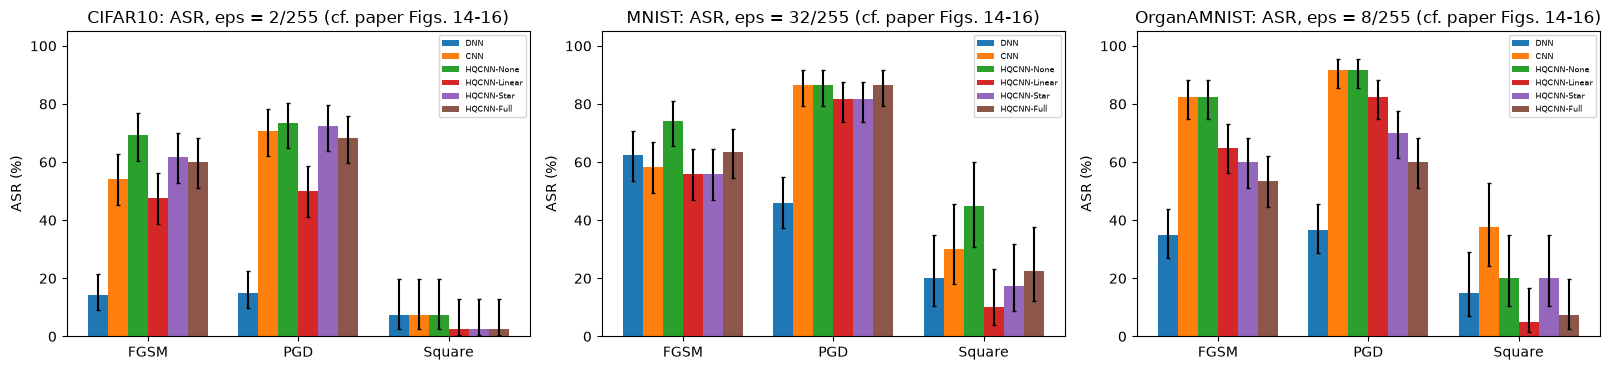

In [16]:
fig, ax = plt.subplots(1, len(DATASETS), figsize=(5.4 * len(DATASETS), 3.8), squeeze=False)
att_names = ["FGSM", "PGD", "Square"]
for j, name in enumerate(DATASETS):
    sub = ATT[(ATT.dataset == name) & (ATT.variant.str.startswith("paper"))]
    wbar = 0.8 / len(MODELS)
    for i, kind in enumerate(MODELS):
        s = sub[sub.model == kind].set_index("attack").loc[att_names]
        ax[0, j].bar(np.arange(3) + (i - len(MODELS) / 2 + 0.5) * wbar, s.ASR, wbar, yerr=[s.ASR - s.ci_lo, s.ci_hi - s.ASR], capsize=1.5, label=kind)
    ax[0, j].set_xticks(range(3)); ax[0, j].set_xticklabels(att_names); ax[0, j].set_ylabel("ASR (%)"); ax[0, j].set_ylim(0, 105)
    ax[0, j].set_title(f"{name}: ASR, eps = {EPS[name]*255:.0f}/255 (cf. paper Figs. 14-16)"); ax[0, j].legend(fontsize=6)
plt.tight_layout(); plt.show()

## 8. Extra experiment: is the robustness real, or is the gradient hidden?
In the authors' forward pass the circuit angles are detached from the autograd graph, so an attacker using `loss.backward()` only sees the classical branch and the fusion weight `alpha`, never the quantum branch. In principle this can hide the gradient from an attacker (gradient masking), which would be a property of the implementation, not of quantum circuits. Our simulator is differentiable, so we can attack the *same trained weights* with the full gradient (`model.differentiable = True`; the random matrix of Algorithm 2 is re-drawn at every step, which is a one-sample expectation-over-transformation). We also measure the cosine between the two gradients.

In [17]:
ADA = []
GRAD = []
for name in DATASETS:
    d = DATA[name]; eps = EPS[name]
    for kind in [k for k in MODELS if k.startswith("HQ")]:
        model = RES[name][kind]["model"]
        x, y = correct_subset(model, d, N_ATTACK)
        # gradient comparison on the attacked images (same random matrix for both)
        model.eval(); model.differentiable = False; torch.manual_seed(SEED); g0 = input_grad(model, x, y).flatten(1)
        model.differentiable = True;  torch.manual_seed(SEED); g1 = input_grad(model, x, y).flatten(1)
        cos = F.cosine_similarity(g0, g1, dim=1)
        GRAD.append(dict(dataset=name, model=kind, mean_cosine_detached_vs_full=cos.mean().item(), norm_ratio_full_over_detached=(g1.norm(dim=1) / g0.norm(dim=1).clamp_min(1e-12)).median().item()))
        for an, fn in [("FGSM", fgsm), ("PGD", pgd)]:
            model.differentiable = True
            r = run_attack(model, fn, x, y, eps=eps)
            model.differentiable = False
            ADA.append(dict(dataset=name, model=kind, attack=an, variant="adaptive (differentiable quantum branch)", **r))
        print(f"[{name}] {kind:13s} adaptive " + " | ".join(f"{a['attack']} {a['ASR']:5.1f}%" for a in ADA[-2:]))
ADA = pd.DataFrame(ADA); GRAD = pd.DataFrame(GRAD)
print("\nGradient of the loss w.r.t. the input, authors' (detached) vs full:"); print(GRAD.round(3).to_string(index=False))
ATT_ALL = pd.concat([ATT, ADA], ignore_index=True)

[CIFAR10] HQCNN-None    adaptive FGSM  68.3% | PGD  70.8%


[CIFAR10] HQCNN-Linear  adaptive FGSM  45.8% | PGD  50.8%


[CIFAR10] HQCNN-Star    adaptive FGSM  61.7% | PGD  74.2%


[CIFAR10] HQCNN-Full    adaptive FGSM  57.5% | PGD  68.3%


[MNIST] HQCNN-None    adaptive FGSM  75.8% | PGD  85.0%


...

[MNIST] HQCNN-Full    adaptive FGSM  60.0% | PGD  84.2%


[OrganAMNIST] HQCNN-None    adaptive FGSM  81.7% | PGD  90.8%


[OrganAMNIST] HQCNN-Linear  adaptive FGSM  67.5% | PGD  79.2%


[OrganAMNIST] HQCNN-Star    adaptive FGSM  60.0% | PGD  63.3%


[OrganAMNIST] HQCNN-Full    adaptive FGSM  51.7% | PGD  59.2%

Gradient of the loss w.r.t. the input, authors' (detached) vs full:
    dataset        model  mean_cosine_detached_vs_full  norm_ratio_full_over_detached
    CIFAR10   HQCNN-None                         0.836                          1.007
    CIFAR10 HQCNN-Linear                         0.757                          1.000
    CIFAR10   HQCNN-Star                         0.859                          1.011
    CIFAR10   HQCNN-Full                         0.856                          1.061
      MNIST   HQCNN-None                         0.974                          1.042
      MNIST HQCNN-Linear                         0.939                          0.989
      MNIST   HQCNN-Star                         0.884                          1.034
      MNIST   HQCNN-Full                         0.896                          1.001
OrganAMNIST   HQCNN-None                         0.914                          1.006
OrganAMNI

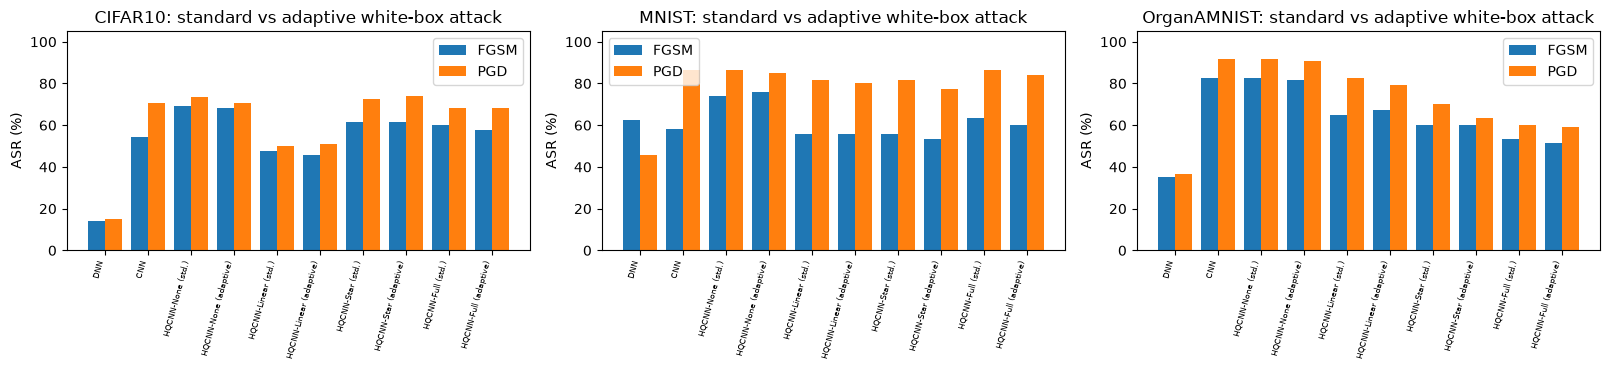

In [18]:
fig, ax = plt.subplots(1, len(DATASETS), figsize=(5.4 * len(DATASETS), 3.8), squeeze=False)
for j, name in enumerate(DATASETS):
    for a_i, an in enumerate(["FGSM", "PGD"]):
        base = ATT_ALL[(ATT_ALL.dataset == name) & (ATT_ALL.attack == an)]
        labels, vals = [], []
        for kind in MODELS:
            labels.append(kind + (" (std.)" if kind.startswith("HQ") else "")); vals.append(base[(base.model == kind) & base.variant.str.startswith("paper")].ASR.iloc[0])
            if kind.startswith("HQ"):
                labels.append(kind + " (adaptive)"); vals.append(base[(base.model == kind) & base.variant.str.startswith("adaptive")].ASR.iloc[0])
        ax[0, j].bar(np.arange(len(vals)) + (a_i - 0.5) * 0.4, vals, 0.4, label=an)
    ax[0, j].set_xticks(np.arange(len(labels))); ax[0, j].set_xticklabels(labels, rotation=75, ha="right", fontsize=6)
    ax[0, j].set_ylabel("ASR (%)"); ax[0, j].set_ylim(0, 105); ax[0, j].set_title(f"{name}: standard vs adaptive white-box attack"); ax[0, j].legend()
plt.tight_layout(); plt.show()

## 9. Cost of generating adversarial examples (Sect. 7.2, Appendix B)
The paper's second claim is that adversarial examples against hybrids are much more expensive to generate. With the authors' per-sample PennyLane loop this is trivially true (about 100 times slower per forward pass). We measure the same ratio for (a) our batched simulator and (b) the authors' original loop on a few images, to show that the "cost" is a property of the simulation, not of the defence.

In [19]:
tt = []
name = DATASETS[0]; d = DATA[name]; eps = EPS[name]
for kind in MODELS:
    s = ATT[(ATT.dataset == name) & (ATT.model == kind) & (ATT.attack == "FGSM")].iloc[0]
    p = ATT[(ATT.dataset == name) & (ATT.model == kind) & (ATT.attack == "PGD")].iloc[0]
    tt.append(dict(model=kind, fgsm_sec_per_image=s.sec_per_image, pgd_sec_per_image=p.sec_per_image))
TT = pd.DataFrame(tt); cnn_row = TT[TT.model == "CNN"].iloc[0]
TT["fgsm_ratio_vs_CNN"] = TT.fgsm_sec_per_image / cnn_row.fgsm_sec_per_image; TT["pgd_ratio_vs_CNN"] = TT.pgd_sec_per_image / cnn_row.pgd_sec_per_image
print(f"{name}: measured with the batched simulator (CPU)"); print(TT.round(5).to_string(index=False))

# the authors' original per-sample circuit loop, 6 images
hq = [k for k in MODELS if k.startswith("HQ")][-1]; model = RES[name][hq]["model"]; x, y = correct_subset(model, d, 6)
model.backend = "pennylane"; torch.manual_seed(SEED); t0 = time.time(); _ = fgsm(model, x, y, eps); t_pl = (time.time() - t0) / len(x)
t_fa = TT[TT.model == hq].fgsm_sec_per_image.iloc[0]      # batched simulator, amortised over the N_ATTACK images attacked above
t_cnn = cnn_row.fgsm_sec_per_image
print(f"\nFGSM seconds/image for {hq}: authors' PennyLane loop {t_pl:.4f} s ({t_pl / t_cnn:.0f}x CNN) vs batched simulator {t_fa:.4f} s ({t_fa / t_cnn:.1f}x CNN, batch of {N_ATTACK}); CNN {t_cnn:.5f} s")

CIFAR10: measured with the batched simulator (CPU)
       model  fgsm_sec_per_image  pgd_sec_per_image  fgsm_ratio_vs_CNN  pgd_ratio_vs_CNN
         DNN             0.00408            0.03068            0.26669           0.32606
         CNN             0.01529            0.09410            1.00000           1.00000
  HQCNN-None             0.01054            0.07538            0.68927           0.80108
HQCNN-Linear             0.00507            0.04984            0.33142           0.52963
  HQCNN-Star             0.01163            0.16694            0.76090           1.77411
  HQCNN-Full             0.01188            0.20805            0.77705           2.21108



FGSM seconds/image for HQCNN-Full: authors' PennyLane loop 0.3325 s (22x CNN) vs batched simulator 0.0119 s (0.8x CNN, batch of 120); CNN 0.01529 s


## 10. Side-by-side comparison with the paper
Paper numbers are read from Fig. 12 (test accuracy) and Figs. 14-16 (ASR, %). Verdict rules: a number is **reproduced** if it is within 2 accuracy points (ODR) or within max(5 points, half-width of our binomial 95 % interval) of the paper's value; otherwise **not reached** (ours lower) or **exceeded** (ours higher); structural claims are judged on the ordering. Our models see only a small subset of the training data and a few epochs, so absolute accuracies are expected to be lower; the point of the table is to show which claims survive that.

In [20]:
PAPER_ODR = {   # Fig. 12, test accuracy (%)
 "MNIST":       {"DNN": 97.09, "CNN": 99.15, "HQCNN-None": 98.21, "HQCNN-Linear": 98.88, "HQCNN-Star": 98.65, "HQCNN-Full": 99.06},
 "OrganAMNIST": {"DNN": 63.89, "CNN": 89.20, "HQCNN-None": 84.31, "HQCNN-Linear": 87.94, "HQCNN-Star": 86.08, "HQCNN-Full": 85.85},
 "CIFAR10":     {"DNN": 48.30, "CNN": 79.70, "HQCNN-None": 77.61, "HQCNN-Linear": 75.27, "HQCNN-Star": 79.53, "HQCNN-Full": 79.59}}
_order = ["FGSM", "PGD", "APGD", "VMIFGSM", "CW", "DeepFool", "OnePixel", "Square"]
_rows = {"MNIST": {"DNN": [78.06,62.36,91.92,47.34,91.22,69.05,1.15,76.67], "CNN": [47.29,53.39,89.82,38.91,89.82,83.26,2.94,51.81],
                   "HQCNN-None": [40.64,45.66,81.96,29.68,18.49,72.15,0.68,9.82], "HQCNN-Linear": [33.33,35.83,74.15,22.00,19.05,71.20,0.68,5.90],
                   "HQCNN-Star": [31.36,33.18,75.45,22.50,9.77,75.00,0.45,7.50], "HQCNN-Full": [23.76,28.73,75.57,16.29,11.09,76.02,0.68,5.66]},
         "OrganAMNIST": {"DNN": [52.73,54.91,55.64,53.82,90.18,89.45,5.09,39.27], "CNN": [53.37,64.77,65.80,63.99,94.04,95.08,4.92,36.79],
                   "HQCNN-None": [51.65,62.09,63.74,62.64,35.44,90.11,5.49,7.42], "HQCNN-Linear": [37.84,51.35,51.62,48.38,19.19,92.43,4.05,3.78],
                   "HQCNN-Star": [42.05,53.91,56.06,53.10,19.68,90.84,4.85,5.93], "HQCNN-Full": [43.01,59.10,57.52,57.52,22.16,88.13,5.54,5.80]},
         "CIFAR10": {"DNN": [26.48,26.88,26.88,26.48,70.75,98.81,4.35,19.37], "CNN": [60.45,72.14,74.63,75.37,98.51,96.27,25.62,30.10],
                   "HQCNN-None": [56.48,69.43,68.39,72.28,67.62,70.21,21.76,1.81], "HQCNN-Linear": [48.97,63.92,63.40,66.49,69.07,67.53,19.07,1.29],
                   "HQCNN-Star": [54.75,68.50,66.50,72.25,72.50,71.25,19.75,2.75], "HQCNN-Full": [51.13,64.66,63.91,65.91,66.67,76.69,16.79,2.51]}}
PAPER_ASR = {ds: {m: dict(zip(_order, v)) for m, v in mm.items()} for ds, mm in _rows.items()}

def verdict(ours, paper, tol):
    if abs(ours - paper) <= tol: return "reproduced"
    return "exceeded (+%.1f)" % (ours - paper) if ours > paper else "not reached (%.1f)" % (ours - paper)

# --- table 1: clean accuracy
t1 = []
for name in DATASETS:
    for k in MODELS:
        o = 100 * RES[name][k]["odr"]; p = PAPER_ODR[name][k]
        t1.append(dict(dataset=name, model=k, paper_ODR=p, notebook_ODR=round(o, 2), verdict=verdict(o, p, 2.0)))
T1 = pd.DataFrame(t1); print("Claim: clean accuracy (Fig. 12)"); print(T1.to_string(index=False))

# --- table 2: ASR of the standard evaluation vs the paper
t2 = []
for name in DATASETS:
    for k in MODELS:
        for an in ["FGSM", "PGD", "Square"]:
            r = ATT[(ATT.dataset == name) & (ATT.model == k) & (ATT.attack == an)].iloc[0]; p = PAPER_ASR[name][k][an]
            tol = max(5.0, (r.ci_hi - r.ci_lo) / 2)
            t2.append(dict(dataset=name, model=k, attack=an, paper_ASR=p, notebook_ASR=round(r.ASR, 1), ci95=f"[{r.ci_lo:.0f},{r.ci_hi:.0f}]", verdict=verdict(r.ASR, p, tol)))
T2 = pd.DataFrame(t2); print("\nClaim: ASR values (Figs. 14-16), standard evaluation"); print(T2.to_string(index=False))

Claim: clean accuracy (Fig. 12)
    dataset        model  paper_ODR  notebook_ODR             verdict
    CIFAR10          DNN      48.30         35.80 not reached (-12.5)
    CIFAR10          CNN      79.70         53.40 not reached (-26.3)
    CIFAR10   HQCNN-None      77.61         45.10 not reached (-32.5)
    CIFAR10 HQCNN-Linear      75.27         23.40 not reached (-51.9)
    CIFAR10   HQCNN-Star      79.53         49.30 not reached (-30.2)
    CIFAR10   HQCNN-Full      79.59         33.00 not reached (-46.6)
      MNIST          DNN      97.09         89.60  not reached (-7.5)
      MNIST          CNN      99.15         92.40  not reached (-6.7)
      MNIST   HQCNN-None      98.21         74.40 not reached (-23.8)
      MNIST HQCNN-Linear      98.88         91.30  not reached (-7.6)
      MNIST   HQCNN-Star      98.65         90.90  not reached (-7.8)
      MNIST   HQCNN-Full      99.06         87.80 not reached (-11.3)
OrganAMNIST          DNN      63.89         63.54         


Claim: ASR values (Figs. 14-16), standard evaluation
    dataset        model attack  paper_ASR  notebook_ASR    ci95             verdict
    CIFAR10          DNN   FGSM      26.48          14.2  [9,22] not reached (-12.3)
    CIFAR10          DNN    PGD      26.88          15.0 [10,22] not reached (-11.9)
    CIFAR10          DNN Square      19.37           7.5  [3,20] not reached (-11.9)
    CIFAR10          CNN   FGSM      60.45          54.2 [45,63]          reproduced
    CIFAR10          CNN    PGD      72.14          70.8 [62,78]          reproduced
    CIFAR10          CNN Square      30.10           7.5  [3,20] not reached (-22.6)
    CIFAR10   HQCNN-None   FGSM      56.48          69.2 [60,77]    exceeded (+12.7)
    CIFAR10   HQCNN-None    PGD      69.43          73.3 [65,80]          reproduced
    CIFAR10   HQCNN-None Square       1.81           7.5  [3,20]          reproduced
    CIFAR10 HQCNN-Linear   FGSM      48.97          47.5 [39,56]          reproduced
    CIFAR10

In [21]:
# --- table 3: the structural claims
claims = []
hq_models = [k for k in MODELS if k.startswith("HQ")]
for name in DATASETS:
    for an in ["FGSM", "PGD", "Square"]:
        std = ATT[(ATT.dataset == name) & (ATT.attack == an)].set_index("model").ASR
        paper_cnn = PAPER_ASR[name]["CNN"][an]; paper_best = min(PAPER_ASR[name][k][an] for k in hq_models)
        ours_cnn = std["CNN"]; ours_best = std[hq_models].min()
        ok = ours_best < ours_cnn
        claims.append(dict(dataset=name, claim=f"best hybrid has lower {an} ASR than CNN (standard attack)", paper=f"{paper_best:.1f} < {paper_cnn:.1f}",
                           notebook=f"{ours_best:.1f} vs {ours_cnn:.1f}", verdict="reproduced" if ok else "not reached"))
    for an in ["FGSM", "PGD"]:
        ad = ADA[(ADA.dataset == name) & (ADA.attack == an)].set_index("model").ASR
        cnn = ATT[(ATT.dataset == name) & (ATT.attack == an) & (ATT.model == "CNN")].ASR.iloc[0]
        claims.append(dict(dataset=name, claim=f"hybrids stay more robust than CNN under the ADAPTIVE {an}", paper="not tested", notebook=f"best hybrid {ad.min():.1f} vs CNN {cnn:.1f}",
                           verdict=("holds" if ad.min() < cnn - 5 else "does not hold: advantage disappears")))
    ovh = [RES[name][k]["odr"] * 100 for k in hq_models]
    claims.append(dict(dataset=name, claim="hybrids keep clean accuracy close to the CNN (within 3 pts)", paper=f"CNN {PAPER_ODR[name]['CNN']:.1f}, hybrids {min(PAPER_ODR[name][k] for k in hq_models):.1f}-{max(PAPER_ODR[name][k] for k in hq_models):.1f}",
                       notebook=f"CNN {RES[name]['CNN']['odr']*100:.1f}, hybrids {min(ovh):.1f}-{max(ovh):.1f}", verdict="reproduced" if RES[name]["CNN"]["odr"] * 100 - min(ovh) <= 3 else "not reached"))
claims.append(dict(dataset="all", claim="generating adversarial examples costs much more against hybrids", paper="~100x per sample (PennyLane loop)",
                   notebook=f"{t_pl / t_cnn:.0f}x with authors' loop, {t_fa / t_cnn:.1f}x with batched simulator", verdict="reproduced for the authors' loop; an artefact of simulation, not of the defence"))
claims.append(dict(dataset="all", claim="APGD, VMI-FGSM, C&W, DeepFool, One-Pixel ASR", paper="Figs. 14-16", notebook="not run", verdict="cannot be checked"))
claims.append(dict(dataset="CIFAR10", claim="HQCNN-Full clean accuracy 79.59 % (headline number)", paper="79.59",
                   notebook=(f"{RES['CIFAR10']['HQCNN-Full']['odr']*100:.2f}" if "CIFAR10" in RES and "HQCNN-Full" in RES["CIFAR10"] else "model not trained in this mode"),
                   verdict=(verdict(RES['CIFAR10']['HQCNN-Full']['odr']*100, 79.59, 2.0) if "CIFAR10" in RES and "HQCNN-Full" in RES["CIFAR10"] else "cannot be checked in FAST mode")))
T3 = pd.DataFrame(claims); pd.set_option("display.max_colwidth", 80); print("Structural claims"); print(T3.to_string(index=False))

Structural claims
    dataset                                                           claim                             paper                                            notebook                                                                         verdict
    CIFAR10       best hybrid has lower FGSM ASR than CNN (standard attack)                       49.0 < 60.5                                        47.5 vs 54.2                                                                      reproduced
    CIFAR10        best hybrid has lower PGD ASR than CNN (standard attack)                       63.9 < 72.1                                        50.0 vs 70.8                                                                      reproduced
    CIFAR10     best hybrid has lower Square ASR than CNN (standard attack)                        1.3 < 30.1                                          2.5 vs 7.5                                                                      reproduced
    CIFAR10   

### How to read the verdict tables
* "reproduced / exceeded / not reached" in the ASR and ODR tables compare one number of ours with one number of the paper under the tolerance stated above; with `N_ATTACK = 120` the tolerance is wide (about +-9 points), so "reproduced" for an ASR is a weak statement.
* The structural rows use the **minimum over the four hybrids** against the single CNN. This favours the paper (the best of four noisy numbers is expected to look better than the CNN even if all five models were equally robust), so also look at the averages: mean hybrid FGSM / PGD ASR is 59.6 / 66.0 % (CIFAR-10), 62.3 / 84.2 % (MNIST) and 65.2 / 76.1 % (OrganAMNIST) against CNN 54.2 / 70.8, 58.3 / 86.7 and 82.5 / 91.7 % (computed from the table in section 7).
* The adaptive-attack rows show that the hybrids' advantage, where it exists, survives a full-gradient attack in this small-scale setting (see section 11 for why this is not evidence of quantum robustness).

## 11. Reading the paper critically

All numbers below are read from the tables printed above (one training seed, 1500 training images, 3 epochs, `N_ATTACK = 120`, binomial 95 % intervals of about +-9 ASR points); compare orderings, not decimals.

* **Clean accuracy is not reproduced at this budget.** Our CNNs reach 53.4 % (CIFAR-10), 92.4 % (MNIST) and 54.3 % (OrganAMNIST) against 79.7 / 99.2 / 89.2 % in the paper, and the hybrids are below the CNN everywhere (CIFAR-10: 23.4-49.3 %, MNIST: 74.4-91.3 %, OrganAMNIST: 18.5-51.3 %). The headline 79.59 % (HQCNN-Full, CIFAR-10) is 33.0 % here. With 3 epochs on 3 % of CIFAR-10 we cannot say whether the paper's "near-parity with the CNN" would appear with 10 epochs on the full data, but under an equal small budget the hybrid trains more slowly and less stably than the CNN.
* **The quantum branch carries no information in the released code.** The 12 encoded angles are small (mean absolute value about 0.2 rad) because Algorithm 2 multiplies a random orthogonal matrix by 0.1 before the tanh. The circuit therefore stays close to |0000> and its class distribution is almost the same for every image: alone it predicts one single class for 100 % of the test images (accuracy exactly 1/K) and the standard deviation of its probabilities across images is about 0.01 (section 6). The fusion network mixes this near-constant vector with the CNN output.
* **Gradient masking through `.detach()` is real in the code but, here, not the explanation.** The authors detach the angles, so an attacker never sees the quantum branch. Our differentiable simulator shows that the full gradient has cosine 0.58-0.99 (mostly above 0.8) with the detached one, and the adaptive FGSM/PGD attack changes the ASR by at most about 7 points (inside the binomial interval) in all 24 hybrid/attack combinations. With a near-constant quantum branch there is little gradient to hide. This does not exclude a larger effect for a trained, informative quantum branch.
* **The ASR reductions of the paper are not reproduced as a robust effect.** For the standard attacks the "best hybrid beats the CNN" rows say reproduced, but that rule takes the minimum over four hybrids against one CNN, which is optimistic. Read directly: on CIFAR-10 three of four hybrids have a *higher* FGSM ASR than the CNN (69.2 / 61.7 / 60.0 % vs 54.2 %), on MNIST PGD ASR is 81.7-86.7 % for hybrids vs 86.7 % for the CNN (paper: 29-46 % vs 53 %), and the large drops appear only on OrganAMNIST, for three of the four hybrids (FGSM 53-65 % vs 82.5 %, PGD 60-82 % vs 91.7 %; HQCNN-None equals the CNN), where those hybrids are also the least accurate models. A lower ASR on correctly classified images is expected for less confident and less stable models, so it should not be read as evidence for a quantum effect.
* **The hybrid is stochastic.** Algorithm 2 draws a new random matrix at every forward pass, so two passes over the same clean test images agree on only 86-99 % of the predictions. Single-shot attack evaluation is therefore noisy, and the Square attack, which accepts an update when a random draw looks better, is handicapped on the hybrids. Our Square numbers are low for *all* models (80 queries on 40 images, the paper uses 500), so that comparison is weak.
* **No adaptive attack in the paper**, although its related-work section stresses that defences must be evaluated against adaptive white-box attacks; all eight attacks run against the non-differentiable pipeline.
* **Noise is tiny.** `p = 0.005` split three ways changes the output probabilities in the third decimal; the circuit is practically a fixed, nearly noiseless map, so the wording "realistic noise" overstates it.
* **Paper vs code mismatches.** Eq. 2 and Figs. 4-7 draw variational rotations `RZ RY RX` (trainable theta); the code applies `RX, RY, RZ` with *data* angles and has no trainable quantum parameter. The paper states neither the qubit count nor the noise strength, and says the hook is on the last feature-producing layer, which in the code is the output `fc` layer.
* **The time-cost argument is about simulation.** The authors' per-sample PennyLane loop costs 22 times a CNN gradient step here (paper: about 100 times on its machine); our batched version of the *same* circuit costs 0.8 times, so the "cost" says nothing about quantum hardware or about the difficulty of attacking the model.

## 12. Exercises
1. Set `NOISE_STRENGTH = 0.05` and `0.2`. Does the accuracy fall? Does the ASR of the standard attack change? Does the adaptive attack still win?
2. In `fast_forward`, replace the random orthogonal expansion of Algorithm 2 by a fixed matrix (draw it once, store it in the model). Is the model still stochastic? How do the Square-attack ASR and the clean accuracy change?
3. Replace `loss = F.cross_entropy(...)` in `input_grad` by a margin loss (as in C&W) and rerun section 8. Which loss gives the strongest attack on the hybrids?
4. Average the adaptive gradient over 10 random draws of the Algorithm-2 matrix (expectation over transformation). How much does the ASR increase compared with one draw?
5. Add the quantum branch's probabilities *only* as a fixed input of the fusion MLP (train it, then freeze): does the hybrid still beat the CNN under the standard attack? What does this say about where the claimed robustness comes from?